# Stage 1 — U-Net super-resolution of turbulent channel-flow fields

**Vamsi Gudipati**

I take 5,777 planes of the streamwise velocity u from a turbulent channel-flow simulation, coarsen each one by a factor of 4, interpolate it back to the fine grid, and train a U-Net to restore the fine field. The main training runs 25 epochs (the notebook sets 50; 25 take about 47 minutes on my laptop's GPU) and is scored against the interpolation it starts from. I ran the notebook's five experiments with a reduced budget (coarsening factor, network width, residual learning, three velocity components, a gradient-based error), added a training animation, and repeated every experiment training with three seeds. Stage 4 sets the trained models against nearest-neighbour and bicubic upscaling and looks at the energy spectrum.

Portfolio page: https://vamsigudipati.github.io/unet-turbulent-fields.html

In [1]:
# Where this notebook reads its data and writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "01_unet_turbulent_superresolution"
DATA_DIR = Path("../release_assets")          # the planes from the first release, and the TFRecords Stage 2 writes
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "01_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# U-Net for Turbulent Field Super-Resolution with TensorFlow/Keras

This notebook introduces U-Nets as **field-to-field models** for CFD data.

In the previous forecasting notebook, we worked with one-dimensional turbulent signals and recurrent models:

```text
past signal window → future signal value
```

In this notebook, we move from one-dimensional signals to two-dimensional turbulent fields.

The goal is to learn a simple super-resolution problem:

```text
coarse turbulent field → refined turbulent field
```

We use 2D `y-x` planes extracted from a 3D turbulent velocity field.

Each plane contains a single velocity component, u

```text
u(y, x)
```

Therefore, each training sample is treated like a one-channel image:

```text
sample shape = (ny, nx, 1)
```

The learning task is:

```text
Input:  coarse/interpolated velocity field
Output: high-resolution velocity field
```

In practice, the coarse field is created artificially from the high-resolution field:

```text
high-resolution field
        ↓
downsampling
        ↓
coarse field
        ↓
upsampling back to the original size
        ↓
U-Net
        ↓
refined field
```

This allows us to train and evaluate the method even when we only have high-resolution DNS-like fields.

We start with a simple U-Net and use Keras-style TensorFlow code.


In [2]:
# Device report: which devices this kernel sees
import tensorflow as tf, platform
print("TensorFlow", tf.__version__, "| Python", platform.python_version())
print("Physical devices:", tf.config.list_physical_devices())
print("GPU (Metal) visible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.18.1 | Python 3.12.14
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU (Metal) visible: True


# 1. Environment

This notebook should run in:

- Google Colab,
- VS Code with Jupyter,
- a local Jupyter installation.

Required packages:

```bash
pip install numpy matplotlib tensorflow h5py ipykernel pydot graphviz
```

You also need graphviz https://graphviz.org/download/

The input files expected by this notebook are the extracted `y-x` planes:

```text
P125_83pi.30000.z.000.u
```

These files are raw binary `float32` files. The metadata file is used to recover the shape of each plane.


In [3]:
# =========================================================
# 1. Import libraries
# =========================================================

from pathlib import Path
import json
import os
import sys

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(0)
tf.random.set_seed(0)

print("TensorFlow version:", tf.__version__)
print("Current working directory:", Path.cwd())

TensorFlow version: 2.18.1
Current working directory: <repo>/notebooks


# 2. Optional: Google Colab Setup

If the notebook is running in Google Colab, we mount Google Drive.

If the notebook is running locally, this cell does nothing except print the current folder.

The goal is to make the notebook portable.


In [4]:
# =========================================================
# 2. Check whether we are running in Google Colab
# =========================================================

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive
    pass  # Google Drive is not mounted here: the data come from release_assets/ (see the data-path cell)
    print("Google Drive mounted.")
else:
    print("This is not Google Colab.")
    print("Current working directory:")
    print(Path.cwd())

Running in Google Colab: False
This is not Google Colab.
Current working directory:
<repo>/notebooks


# 3. Define Data Paths

The raw 3D field was previously sliced into several `y-x` planes at fixed `z`.

The original Windows folder was:


<data_root>


The extracted planes are expected in:

```text
<data_root>\yx_planes
```

In Google Colab, you should replace the path by the corresponding Google Drive path.



In [5]:
# =========================================================
# 3. Define data paths
# =========================================================

base_name = "P125_83pi"

data_dir = DATA_DIR  # the planes from the repository's first release, extracted into release_assets/

planes_dir = data_dir / "u_yx_planes_h5"

print("Data directory:")
print(data_dir)

print("\nPlanes directory:")
print(planes_dir)


print("\nPlanes directory exists:", planes_dir.exists())

if planes_dir.exists():
    print("\nFirst files in planes directory:")
    for item in sorted(planes_dir.iterdir())[:10]:
        print(" -", item.name)

Data directory:
../release_assets

Planes directory:
../release_assets/u_yx_planes_h5

Planes directory exists: True

First files in planes directory:


 - P125_83pi.30000.000.h5
 - P125_83pi.30000.001.h5
 - P125_83pi.30000.002.h5
 - P125_83pi.30000.003.h5
 - P125_83pi.30000.004.h5
 - P125_83pi.30000.005.h5
 - P125_83pi.30000.006.h5
 - P125_83pi.30000.007.h5
 - P125_83pi.30000.008.h5
 - P125_83pi.30000.009.h5


# 4. Utility Functions: Finding and Reading HDF5 Planes

Before doing anything else, we define the two low-level utilities that the rest of the
notebook depends on:

```text
find_available_h5_planes(...)  -> lists which (snapshot, z-plane) files exist on disk
read_velocity_plane_from_h5(...) -> reads one u(y, x) plane from a single HDF5 file
```

These two functions are defined **once, here**, and reused everywhere else in the notebook
(dataset visualization, dataset construction, etc.). Earlier versions of this notebook
re-defined slightly different versions of these functions further down, which is a common
source of bugs (two functions with the same name but different file-name parsing rules).
Keeping a single definition avoids that.


In [6]:
# =========================================================
# 5. Find available independent HDF5 u planes
# =========================================================

from pathlib import Path
import re
import h5py
import numpy as np

def find_available_h5_planes(
    planes_dir,
    prefix="P125_83pi",
    first_snapshot=30000
):
    """
    Find all independent HDF5 u-plane files.

    Expected file names:

        P125_83pi.30000.000.h5
        P125_83pi.30000.001.h5
        P125_83pi.30001.000.h5
        ...

    Returns
    -------
    plane_files:
        List of dictionaries. Each dictionary contains:

            snapshot_number
            z_label
            z_index
            file_path
    """

    planes_dir = Path(planes_dir)

    pattern = re.compile(
        rf"^{re.escape(prefix)}\.(\d+)\.(\d{{3}})\.h5$"
    )

    plane_files = []

    for file_path in planes_dir.glob(f"{prefix}.*.*.h5"):

        match = pattern.match(file_path.name)

        if match is None:
            continue

        snapshot_number = int(match.group(1))
        z_label = match.group(2)
        z_index = int(z_label)

        if snapshot_number >= first_snapshot:

            plane_files.append(
                {
                    "snapshot_number": snapshot_number,
                    "z_label": z_label,
                    "z_index": z_index,
                    "file_path": file_path
                }
            )

    plane_files = sorted(
        plane_files,
        key=lambda item: (item["snapshot_number"], item["z_index"])
    )

    return plane_files


plane_files = find_available_h5_planes(
    planes_dir=planes_dir,
    prefix="P125_83pi",
    first_snapshot=30000
)

print("Number of HDF5 u planes found:", len(plane_files))

print("\nFirst files:")
for item in plane_files[:5]:
    print(item["snapshot_number"], item["z_label"], item["file_path"].name)

print("\nLast files:")
for item in plane_files[-5:]:
    print(item["snapshot_number"], item["z_label"], item["file_path"].name)

Number of HDF5 u planes found: 5777

First files:
30000 000 P125_83pi.30000.000.h5
30000 001 P125_83pi.30000.001.h5
30000 002 P125_83pi.30000.002.h5
30000 003 P125_83pi.30000.003.h5
30000 004 P125_83pi.30000.004.h5

Last files:
30106 045 P125_83pi.30106.045.h5
30106 046 P125_83pi.30106.046.h5
30106 047 P125_83pi.30106.047.h5
30106 048 P125_83pi.30106.048.h5
30106 049 P125_83pi.30106.049.h5


In [7]:
# =========================================================
# Read one independent HDF5 u plane
# =========================================================

def read_velocity_plane_from_h5(
    h5_file,
    dtype=np.float32,
    add_channel=True,
    return_metadata=False
):
    """
    Read one independent HDF5 y-x plane containing only u.

    Expected internal structure:

        /u    shape = (n_y, n_x)
        /y    shape = (n_y,)

    Returns
    -------
    field:
        If add_channel=True:

            shape = (n_y, n_x, 1)

        If add_channel=False:

            shape = (n_y, n_x)
    """

    h5_file = Path(h5_file)

    if not h5_file.exists():
        raise FileNotFoundError(f"File not found: {h5_file}")

    with h5py.File(h5_file, "r") as f:

        if "u" not in f:
            raise KeyError(f"Dataset 'u' not found in {h5_file}")

        u = f["u"][:].astype(dtype)

        metadata = dict(f.attrs)

        n_y, n_x = u.shape

        metadata["h5_file"] = str(h5_file)
        metadata["file_name"] = h5_file.name
        metadata["plane_shape"] = (int(n_y), int(n_x))
        metadata["n_y"] = int(n_y)
        metadata["n_x"] = int(n_x)
        metadata["u_dtype"] = str(f["u"].dtype)

        if "y" in f:
            metadata["y_shape"] = f["y"].shape
            metadata["y_dtype"] = str(f["y"].dtype)

    if add_channel:
        field = u[..., np.newaxis]
    else:
        field = u

    field = field.astype(np.float32)

    if return_metadata:
        return field, metadata

    return field

In [8]:
# =========================================================
# Read one example plane
# =========================================================

example_item = plane_files[0]

example_field, example_metadata = read_velocity_plane_from_h5(
    h5_file=example_item["file_path"],
    return_metadata=True
)

print("File used:")
print(example_metadata["file_name"])

print("\nSnapshot number:", example_item["snapshot_number"])
print("z label:", example_item["z_label"])

print("\nExample field shape:", example_field.shape)
print("dtype:", example_field.dtype)

print("\nMetadata:")
for key, value in example_metadata.items():
    print(f"{key}: {value}")

values = example_field[:, :, 0]

print("\nChannel statistics:")
print(
    "u",
    "min:", values.min(),
    "max:", values.max(),
    "mean:", values.mean(),
    "std:", values.std()
)

File used:
P125_83pi.30000.000.h5

Snapshot number: 30000
z label: 000

Example field shape: (201, 384, 1)
dtype: float32

Metadata:
Re: 2100.0
alp: 0.25
bet: 0.6666666666666666
compression: gzip
compression_opts: 4
dataset_layout: u[y_index, x_index]
description: Single y-x plane of the u velocity component.
dtype: float32
mx: 384
my: 201
mz: 288
n_x: 384
n_y: 201
n_z_total: 288
original_axis_order: (y, z, x)
original_dataset_name: u
original_shape: (201, 288, 384)
output_axis_order: (y, x)
output_dataset_name: u
plane_shape: (201, 384)
plane_type: y-x plane at fixed z index
snapshot_number: 30000
source_file: P125_83pi.30000.h5.uvw
source_path: <source_dir>\P125_83pi.30000.h5.uvw
time: 66.25142812728882
variable: u
vcon: 0.0
z_index: 0
z_label: 000
h5_file: ../release_assets/u_yx_planes_h5/P125_83pi.30000.000.h5
file_name: P125_83pi.30000.000.h5
u_dtype: float32
y_shape: (201,)
y_dtype: float64

Channel statistics:
u min: -9.594627e-10 max: 1.2092234 mean: 0.8369324 std: 0.31576225


# 5. Visualize One High-Resolution Field

Before training any model, we inspect one velocity plane, using the `plane_files` and
`example_field` already obtained in Section 4.

This helps us check that:

```text
1. the files were read correctly,
2. the shape is correct,
3. the field looks physically reasonable.
```


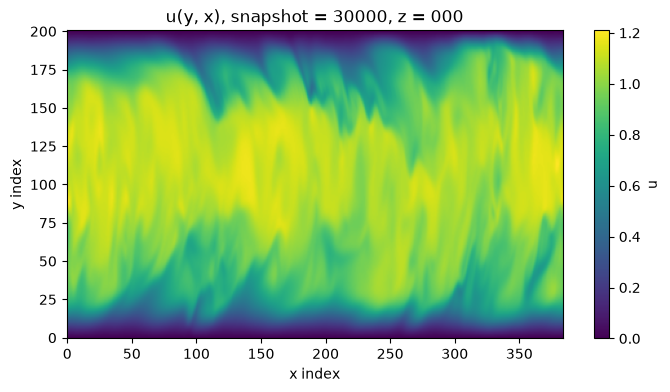

In [9]:
# =========================================================
# Visualize one high-resolution u plane
# =========================================================
#
# We reuse `plane_files` and `example_field` / `example_metadata`
# from Section 4 instead of re-scanning the folder and re-reading
# the file again.

snapshot_number = example_metadata.get(
    "snapshot_number",
    example_item["snapshot_number"]
)

z_label = example_metadata.get(
    "z_label",
    example_item["z_label"]
)

plt.figure(figsize=(8, 4))

plt.imshow(
    example_field[:, :, 0],
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="u")
plt.xlabel("x index")
plt.ylabel("y index")
plt.title(f"u(y, x), snapshot = {snapshot_number}, z = {z_label}")
plt.show()


# 6. Padding the Field Size

The original plane shape is:

```text
(201, 384)
```

A standard U-Net uses several downsampling operations.

If we downsample by a factor of 2 several times, it is convenient for the image dimensions to be divisible by:

```text
2, 4, 8, 16, ...
```

The `x` direction is already convenient:

```text
384 is divisible by 16
```

The `y` direction is not:

```text
201 is not divisible by 16
```

Therefore, we pad the field in the `y` direction up to the next multiple of 16.

For this case:

```text
201 → 208
```

The neural network will work with the padded field:

```text
(208, 384, 1)
```

After prediction, we can crop the result back to the original size if needed.


In [10]:
# =========================================================
# Padding utilities
# =========================================================

def next_multiple(value, multiple):
    """
    Return the smallest multiple of 'multiple' greater than or equal to 'value'.
    """
    return int(np.ceil(value / multiple) * multiple)


def pad_field_to_multiple(field, multiple=16):
    """
    Pad a 2D or 3D field so that height and width are multiples of 'multiple'.

    Input shape:
        (n_y, n_x, channels)

    Output shape:
        (n_y_padded, n_x_padded, channels)
    """

    n_y, n_x = field.shape[:2]

    n_y_padded = next_multiple(n_y, multiple)
    n_x_padded = next_multiple(n_x, multiple)

    pad_y = n_y_padded - n_y
    pad_x = n_x_padded - n_x

    padded = np.pad(
        field,
        pad_width=((0, pad_y), (0, pad_x), (0, 0)),
        mode="edge"
    )

    return padded.astype(np.float32)


def crop_field_to_original_size(field, original_shape):
    """
    Crop a padded field back to the original spatial size.

    Parameters
    ----------
    field:
        Padded field with shape (n_y_padded, n_x_padded, channels).

    original_shape:
        Original spatial shape, for example (201, 384).
    """

    n_y, n_x = original_shape

    return field[:n_y, :n_x, :]


# ---------------------------------------------------------
# Get original plane shape directly from the loaded field
# ---------------------------------------------------------

plane_shape = example_field.shape[:2]

example_field_padded = pad_field_to_multiple(
    example_field,
    multiple=16
)

print("Original field shape:", example_field.shape)
print("Original plane shape:", plane_shape)
print("Padded field shape:", example_field_padded.shape)

example_field_cropped = crop_field_to_original_size(
    example_field_padded,
    original_shape=plane_shape
)

print("Cropped field shape:", example_field_cropped.shape)

Original field shape: (201, 384, 1)
Original plane shape: (201, 384)
Padded field shape: (208, 384, 1)
Cropped field shape: (201, 384, 1)


# 7. Create a Coarse Field

For supervised super-resolution, we need pairs:

```text
coarse field → high-resolution field
```

Since we have a high-resolution field, we can create the coarse input artificially:

```text
high-resolution field
        ↓
downsampling
        ↓
coarse field
        ↓
upsampling
        ↓
coarse field on the original grid
```

The U-Net receives the upsampled coarse field as input.

The target is the original high-resolution field.

The degradation factor controls how much information is removed.

For example:

```text
super_resolution_factor = 4
```

means:

```text
(208, 384) → (52, 96) → (208, 384)
```


In [11]:
# =========================================================
# Create coarse/interpolated fields
# =========================================================

def create_coarse_input(
    high_field,
    super_resolution_factor=4,
    down_method="area",
    up_method="bilinear"
):
    """
    Create a coarse/interpolated version of a high-resolution field.

    Returns:
        coarse_up: same size as high_field
        coarse: true low-resolution field before upsampling
    """

    high_field_tf = tf.convert_to_tensor(
        high_field[None, ...],
        dtype=tf.float32
    )

    ny, nx = high_field.shape[:2]

    coarse_size = (
        ny // super_resolution_factor,
        nx // super_resolution_factor
    )

    # Downsample high-resolution field to a coarse grid.
    coarse = tf.image.resize(
        high_field_tf,
        size=coarse_size,
        method=down_method
    )

    # Upsample coarse field back to the original grid size.
    coarse_up = tf.image.resize(
        coarse,
        size=(ny, nx),
        method=up_method
    )

    coarse = coarse.numpy()[0]
    coarse_up = coarse_up.numpy()[0]

    return coarse_up.astype(np.float32), coarse.astype(np.float32)


super_resolution_factor = 4

example_coarse_up, example_coarse = create_coarse_input(
    example_field_padded,
    super_resolution_factor=super_resolution_factor
)

print("High-resolution padded field:", example_field_padded.shape)
print("Coarse field:", example_coarse.shape)
print("Coarse upsampled field:", example_coarse_up.shape)

High-resolution padded field: (208, 384, 1)
Coarse field: (52, 96, 1)
Coarse upsampled field: (208, 384, 1)


2026-10-13 04:58:02.822557: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 04:58:02.822581: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 04:58:02.822585: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791881882.822599 46287691 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791881882.822618 46287691 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


# 8. Visualize the Super-Resolution Pair

We compare:

```text
1. high-resolution target
2. coarse/interpolated input
3. missing residual
```

The residual is:

```text
residual = high-resolution field - coarse/interpolated field
```

This residual contains much of the small-scale information removed by downsampling.

A useful training strategy is to make the U-Net learn this residual instead of learning the full field directly.


example_field_padded shape: (208, 384, 1)
example_coarse_up shape: (208, 384, 1)


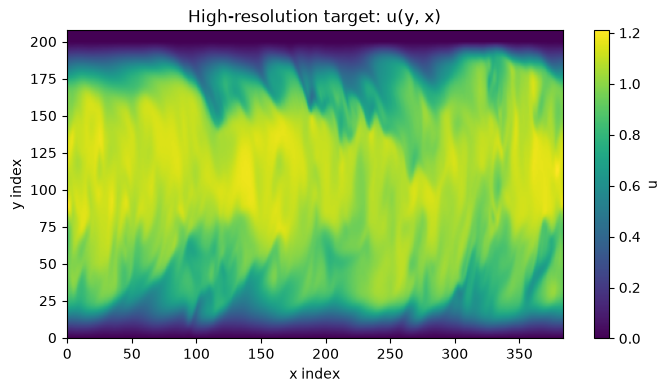

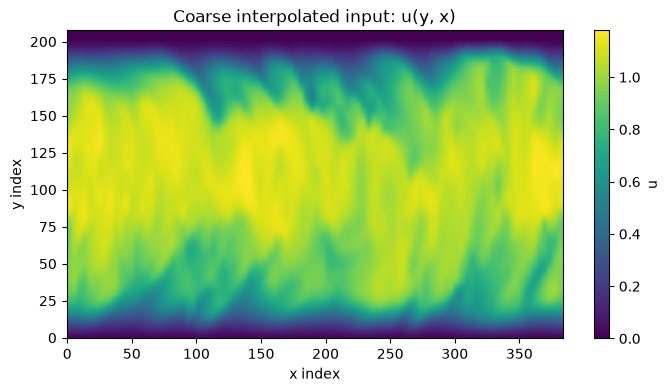

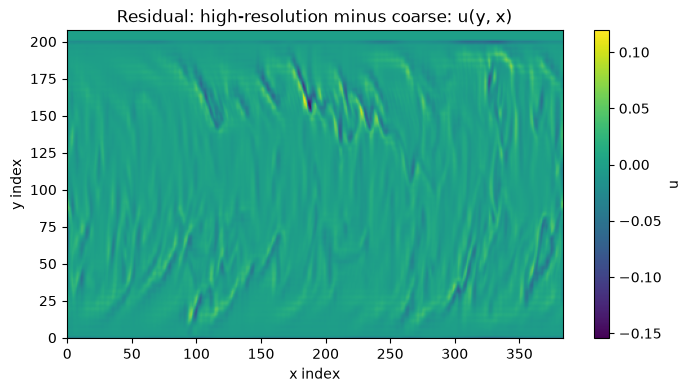

In [12]:
# =========================================================
# Visualize high-resolution, coarse, and residual u fields
# =========================================================

component_name = "u"
component_index = 0

# ---------------------------------------------------------
# Safety checks
# ---------------------------------------------------------

print("example_field_padded shape:", example_field_padded.shape)
print("example_coarse_up shape:", example_coarse_up.shape)

# Make sure both arrays have a channel dimension
if example_field_padded.ndim == 2:
    example_field_padded = example_field_padded[..., np.newaxis]

if example_coarse_up.ndim == 2:
    example_coarse_up = example_coarse_up[..., np.newaxis]

# Check that both fields have the same shape
if example_field_padded.shape != example_coarse_up.shape:
    raise ValueError(
        "Shape mismatch: "
        f"example_field_padded has shape {example_field_padded.shape}, "
        f"but example_coarse_up has shape {example_coarse_up.shape}"
    )

# ---------------------------------------------------------
# Compute residual
# ---------------------------------------------------------
#
# The residual contains the information removed by the
# coarse-graining/interpolation process.

residual_example = example_field_padded - example_coarse_up

# ---------------------------------------------------------
# Extract scalar u fields
# ---------------------------------------------------------

u_high = example_field_padded[:, :, component_index]
u_coarse = example_coarse_up[:, :, component_index]
u_residual = residual_example[:, :, component_index]

# ---------------------------------------------------------
# Plot fields
# ---------------------------------------------------------

fields_to_plot = [
    (u_high, "High-resolution target"),
    (u_coarse, "Coarse interpolated input"),
    (u_residual, "Residual: high-resolution minus coarse")
]

for field, title in fields_to_plot:

    plt.figure(figsize=(8, 4))

    plt.imshow(
        field,
        origin="lower",
        aspect="auto"
    )

    plt.colorbar(label=component_name)
    plt.xlabel("x index")
    plt.ylabel("y index")
    plt.title(f"{title}: {component_name}(y, x)")
    plt.show()

# 9. Build the Full Dataset (Load All Planes)

For this first stage, the dataset is small enough to load all extracted planes into memory.

Each original 2D plane has shape:

```text
(201, 384, 1)
```

After padding:

```text
(208, 384, 1)
```

For each `z` plane we create:

```text
X → coarse/interpolated field
y → high-resolution field
```

The resulting arrays have shape:

```text
X.shape = (samples, 208, 384, 1)
y.shape = (samples, 208, 384, 1)
```

where:

```text
samples = number of z planes
```


In [13]:
# =========================================================
# Build the super-resolution dataset from independent HDF5 u planes
# =========================================================

def build_super_resolution_dataset(
    plane_files,
    super_resolution_factor=4,
    padding_multiple=16,
    max_planes=None
):
    """
    Build a dataset for turbulent field super-resolution using
    independent HDF5 files.

    Each input file contains one u(y, x) plane:

        /u    shape = (n_y, n_x)
        /y    shape = (n_y,)

    For each plane:
        1. read u(y, x) from the HDF5 file,
        2. add a channel dimension -> (n_y, n_x, 1),
        3. pad to a U-Net-friendly size,
        4. create a coarse/interpolated input,
        5. use the padded high-resolution field as the target.

    The learning task is:

        coarse u field -> high-resolution u field

    Returns
    -------
    X:
        Coarse/interpolated input fields.
        Shape: (samples, n_y_padded, n_x_padded, 1)

    y:
        High-resolution target fields.
        Shape: (samples, n_y_padded, n_x_padded, 1)

    used_plane_files:
        List with the metadata of the files actually used.
    """

    X_list = []
    y_list = []
    used_plane_files = []

    if max_planes is not None:
        plane_files_to_use = plane_files[:max_planes]
    else:
        plane_files_to_use = plane_files

    print("Number of plane files to use:", len(plane_files_to_use))

    for index, plane_item in enumerate(plane_files_to_use):

        # -------------------------------------------------
        # Get file path and metadata from the plane list
        # -------------------------------------------------

        h5_file = plane_item["file_path"]

        snapshot_number = plane_item.get("snapshot_number", "unknown")
        z_label = plane_item.get("z_label", "unknown")

        # -------------------------------------------------
        # Read high-resolution u plane
        # -------------------------------------------------
        #
        # high_field shape:
        #
        #     (n_y, n_x, 1)

        high_field, metadata = read_velocity_plane_from_h5(
            h5_file=h5_file,
            add_channel=True,
            return_metadata=True
        )

        # -------------------------------------------------
        # Pad field
        # -------------------------------------------------
        #
        # Example:
        #
        #     (201, 384, 1) -> (208, 384, 1)

        high_field_padded = pad_field_to_multiple(
            high_field,
            multiple=padding_multiple
        )

        # -------------------------------------------------
        # Create coarse/interpolated input
        # -------------------------------------------------
        #
        # coarse_up has the same shape as high_field_padded.
        #
        # Example:
        #
        #     high_field_padded -> downsample -> upsample -> coarse_up

        coarse_up, _ = create_coarse_input(
            high_field_padded,
            super_resolution_factor=super_resolution_factor
        )

        # -------------------------------------------------
        # Store input and target
        # -------------------------------------------------

        X_list.append(coarse_up.astype(np.float32))
        y_list.append(high_field_padded.astype(np.float32))

        used_plane_files.append(
            {
                "file_path": h5_file,
                "file_name": h5_file.name,
                "snapshot_number": snapshot_number,
                "z_label": z_label,
                "metadata": metadata
            }
        )

        if index % 25 == 0:
            print(
                f"Processed plane {index + 1}/{len(plane_files_to_use)}: "
                f"snapshot = {snapshot_number}, z = {z_label}, "
                f"file = {h5_file.name}"
            )

    X = np.asarray(X_list, dtype=np.float32)
    y = np.asarray(y_list, dtype=np.float32)

    return X, y, used_plane_files

In [14]:
# =========================================================
# Build dataset
# =========================================================

X_raw, y_raw, used_plane_files = build_super_resolution_dataset(
    plane_files=plane_files,
    super_resolution_factor=super_resolution_factor,
    padding_multiple=16,
    max_planes=None
)

print("\nDataset created.")
print("X_raw shape:", X_raw.shape)
print("y_raw shape:", y_raw.shape)
print("Number of planes used:", len(used_plane_files))

Number of plane files to use: 5777
Processed plane 1/5777: snapshot = 30000, z = 000, file = P125_83pi.30000.000.h5
Processed plane 26/5777: snapshot = 30000, z = 025, file = P125_83pi.30000.025.h5


Processed plane 51/5777: snapshot = 30001, z = 000, file = P125_83pi.30001.000.h5
Processed plane 76/5777: snapshot = 30001, z = 025, file = P125_83pi.30001.025.h5


Processed plane 101/5777: snapshot = 30002, z = 000, file = P125_83pi.30002.000.h5
Processed plane 126/5777: snapshot = 30002, z = 025, file = P125_83pi.30002.025.h5


Processed plane 151/5777: snapshot = 30003, z = 000, file = P125_83pi.30003.000.h5
Processed plane 176/5777: snapshot = 30003, z = 025, file = P125_83pi.30003.025.h5


Processed plane 201/5777: snapshot = 30004, z = 000, file = P125_83pi.30004.000.h5
Processed plane 226/5777: snapshot = 30004, z = 025, file = P125_83pi.30004.025.h5


...

Processed plane 5626/5777: snapshot = 30103, z = 048, file = P125_83pi.30103.048.h5
Processed plane 5651/5777: snapshot = 30104, z = 023, file = P125_83pi.30104.023.h5


Processed plane 5676/5777: snapshot = 30104, z = 048, file = P125_83pi.30104.048.h5
Processed plane 5701/5777: snapshot = 30105, z = 023, file = P125_83pi.30105.023.h5


Processed plane 5726/5777: snapshot = 30105, z = 048, file = P125_83pi.30105.048.h5
Processed plane 5751/5777: snapshot = 30106, z = 023, file = P125_83pi.30106.023.h5


Processed plane 5776/5777: snapshot = 30106, z = 048, file = P125_83pi.30106.048.h5



Dataset created.
X_raw shape: (5777, 208, 384, 1)
y_raw shape: (5777, 208, 384, 1)
Number of planes used: 5777


# 10. Train / Validation / Test Split

We split the planes into:

```text
training set
validation set
test set
```

We keep the order of the `z` planes.

For a first example, this is simple and reproducible.

Later, we may want to split more carefully if we have several snapshots in time.


In [15]:
# =========================================================
# Train / validation / test split
# =========================================================

def split_train_val_test(
    X,
    y,
    train_fraction=0.70,
    val_fraction=0.15
):
    """Order-preserving split."""

    n_samples = len(X)

    n_train = int(train_fraction * n_samples)
    n_val = int(val_fraction * n_samples)

    X_train = X[:n_train]
    y_train = y[:n_train]

    X_val = X[n_train:n_train + n_val]
    y_val = y[n_train:n_train + n_val]

    X_test = X[n_train + n_val:]
    y_test = y[n_train + n_val:]

    return X_train, X_val, X_test, y_train, y_val, y_test


X_train_raw, X_val_raw, X_test_raw, y_train_raw, y_val_raw, y_test_raw = split_train_val_test(
    X_raw,
    y_raw,
    train_fraction=0.70,
    val_fraction=0.15
)

print("X_train_raw:", X_train_raw.shape)
print("y_train_raw:", y_train_raw.shape)

print("\nX_val_raw:", X_val_raw.shape)
print("y_val_raw:", y_val_raw.shape)

print("\nX_test_raw:", X_test_raw.shape)
print("y_test_raw:", y_test_raw.shape)

X_train_raw: (4043, 208, 384, 1)
y_train_raw: (4043, 208, 384, 1)

X_val_raw: (866, 208, 384, 1)
y_val_raw: (866, 208, 384, 1)

X_test_raw: (868, 208, 384, 1)
y_test_raw: (868, 208, 384, 1)


# 11. Normalize the Velocity Field

Neural networks train better when the inputs and outputs are normalized.

We compute one mean and one standard deviation per velocity component using only the training set.

This avoids information leakage from the validation and test sets.

The normalization is:

```text
normalized field = (field - training_mean) / training_std
```

The same statistics are used for:

```text
training
validation
test
```


In [16]:
# =========================================================
# Normalize using training statistics only
# =========================================================

# Compute one mean and one standard deviation per channel.
# We only have one channel (u), so:
# Shape:
#     channel_mean -> (1, 1, 1, 1)
#     channel_std  -> (1, 1, 1, 1)

channel_mean = y_train_raw.mean(axis=(0, 1, 2), keepdims=True)
channel_std = y_train_raw.std(axis=(0, 1, 2), keepdims=True)

# Avoid division by zero.
channel_std = np.where(channel_std == 0.0, 1.0, channel_std)

print("Channel mean:", channel_mean.reshape(-1))
print("Channel std:", channel_std.reshape(-1))

# Normalize inputs and targets using the same statistics.
X_train = (X_train_raw - channel_mean) / channel_std
X_val = (X_val_raw - channel_mean) / channel_std
X_test = (X_test_raw - channel_mean) / channel_std

y_train = (y_train_raw - channel_mean) / channel_std
y_val = (y_val_raw - channel_mean) / channel_std
y_test = (y_test_raw - channel_mean) / channel_std

print("\nNormalized arrays:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Channel mean: [0.7843925]
Channel std: [0.34103304]



Normalized arrays:
X_train: (4043, 208, 384, 1)
y_train: (4043, 208, 384, 1)
X_val: (866, 208, 384, 1)
y_val: (866, 208, 384, 1)
X_test: (868, 208, 384, 1)
y_test: (868, 208, 384, 1)


# 12. Create TensorFlow Datasets

We now convert the NumPy arrays into TensorFlow datasets.

This gives us:

```text
train_ds
val_ds
test_ds
```

The training dataset is shuffled.

The validation and test datasets are not shuffled.


In [17]:
# =========================================================
# Create TensorFlow datasets
# =========================================================

batch_size = 4
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=0)
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_val, y_val))
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_test, y_test))
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

for batch_x, batch_y in train_ds.take(1):
    print("Batch X shape:", batch_x.shape)
    print("Batch y shape:", batch_y.shape)

Batch X shape: (4, 208, 384, 1)
Batch y shape: (4, 208, 384, 1)


2026-10-13 04:58:50.807546: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


# 13. Baseline: Interpolation Error

Before training a U-Net, we evaluate the input itself.

The input is the coarse field interpolated back to the high-resolution grid.

Therefore, the baseline prediction is simply:

```text
prediction = coarse interpolated input
```

The U-Net should improve this baseline.


In [18]:
# =========================================================
# Baseline interpolation error
# =========================================================

# In normalized variables, the baseline prediction is X_test.
#
# X_test: coarse/interpolated input
# y_test: high-resolution target
#
# Both should have shape:
#
#     (samples, n_y, n_x, 1)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

if X_test.shape != y_test.shape:
    raise ValueError(
        f"Shape mismatch: X_test has shape {X_test.shape}, "
        f"but y_test has shape {y_test.shape}"
    )

baseline_error = y_test - X_test

baseline_mse = np.mean(baseline_error ** 2)
baseline_mae = np.mean(np.abs(baseline_error))

print("Baseline interpolation MSE:", baseline_mse)
print("Baseline interpolation MAE:", baseline_mae)

# ---------------------------------------------------------
# Error for u only
# ---------------------------------------------------------

u_baseline_mae = np.mean(
    np.abs(y_test[:, :, :, 0] - X_test[:, :, :, 0])
)

u_baseline_mse = np.mean(
    (y_test[:, :, :, 0] - X_test[:, :, :, 0]) ** 2
)

print(f"Baseline MSE for u: {u_baseline_mse:.6f}")
print(f"Baseline MAE for u: {u_baseline_mae:.6f}")

X_test shape: (868, 208, 384, 1)
y_test shape: (868, 208, 384, 1)
Baseline interpolation MSE: 0.0013184553
Baseline interpolation MAE: 0.023546778


Baseline MSE for u: 0.001318
Baseline MAE for u: 0.023547


# 14. U-Net Architecture: Building Blocks

A U-Net is an encoder-decoder convolutional network with **skip connections**.

```text
input field
    |
encoder (downsampling path)
    |
bottleneck
    |
decoder (upsampling path)
    |
output field
```

- The **encoder** repeatedly applies convolutions and then halves the spatial resolution
  (`MaxPooling2D`) while doubling the number of filters. This builds up features that
  describe increasingly large-scale, increasingly abstract structures.
- The **bottleneck** is the deepest, most compressed representation of the field.
- The **decoder** mirrors the encoder: it upsamples back to the original resolution
  (`Conv2DTranspose`) while halving the number of filters again.
- The **skip connections** copy the encoder feature maps at each resolution level and
  concatenate them into the decoder at the matching level. Without them, the fine-grained
  spatial detail lost during downsampling could not be recovered — the bottleneck alone
  is too compressed to reconstruct small-scale turbulent structures accurately.

Below we implement this as three reusable building blocks: `conv_block`,
`encoder_block`, and `decoder_block`. The full model in Section 15 is just these
blocks stacked symmetrically.


In [19]:
# =========================================================
# U-Net building blocks
# =========================================================
#
# The whole U-Net is built out of three small, reusable pieces:
#
#   conv_block()    -> two 3x3 convolutions (feature extraction at a fixed resolution)
#   encoder_block()  -> conv_block() + downsampling (halves H and W)
#   decoder_block()  -> upsampling + skip connection + conv_block() (doubles H and W)
#
# The full model (Section 15) calls encoder_block() four times going down,
# one conv_block() at the bottleneck, and decoder_block() four times going
# back up, mirroring the encoder level by level.


def conv_block(
    x,
    filters,
    kernel_size=3,
    activation="relu",
    padding="same",
    dropout_rate=0.0
):
    """
    Basic convolutional block used in the U-Net.

    It applies:
        Conv2D -> Conv2D -> optional Dropout

    Two stacked 3x3 convolutions give an effective 5x5 receptive field at this
    resolution level, while keeping the number of parameters and the cost per
    layer small. `padding="same"` keeps the spatial size (H, W) unchanged, so
    this block never changes the resolution -- only encoder_block/decoder_block
    do that (see below). This is what lets the output of this block be reused
    as a skip connection: its shape always matches the corresponding decoder level.
    """

    x = tf.keras.layers.Conv2D(
        filters=filters,
        kernel_size=kernel_size,
        activation=activation,
        padding=padding,
        kernel_initializer="he_normal"
    )(x)

    x = tf.keras.layers.Conv2D(
        filters=filters,
        kernel_size=kernel_size,
        activation=activation,
        padding=padding,
        kernel_initializer="he_normal"
    )(x)

    if dropout_rate > 0.0:
        x = tf.keras.layers.Dropout(dropout_rate)(x)

    return x


def encoder_block(
    x,
    filters,
    dropout_rate=0.0
):
    """
    One level of the encoder (downsampling path).

    Steps:
        1. conv_block()      -> extract features at the CURRENT resolution
        2. MaxPooling2D(2,2) -> halve H and W for the NEXT (deeper) level

    Returns two tensors:
        skip -> features at the current resolution, BEFORE pooling.
                Kept aside and later concatenated into the matching
                decoder_block() (this is the "skip connection").
        down -> the pooled, lower-resolution tensor that feeds into the
                next encoder level (or into the bottleneck).

    Called four times in the model (Section 15), with the number of filters
    doubling each time: base_filters -> 2x -> 4x -> 8x. As resolution goes
    down, filter count goes up, keeping the amount of information roughly
    balanced across levels.
    """

    skip = conv_block(
        x,
        filters=filters,
        dropout_rate=dropout_rate
    )

    down = tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    )(skip)

    return skip, down


def decoder_block(
    x,
    skip,
    filters,
    dropout_rate=0.0
):
    """
    One level of the decoder (upsampling path). Mirrors encoder_block().

    Steps:
        1. Conv2DTranspose(stride=2) -> double H and W (undo one pooling step)
        2. Concatenate([upsampled, skip]) -> merge with the encoder features
           saved at the SAME resolution level in encoder_block(). This is
           where the skip connection is actually used: it re-injects the
           fine spatial detail that pooling removed on the way down.
        3. conv_block() -> mix the concatenated features together

    Called four times in the model (Section 15), with the number of filters
    halving each time (mirroring the encoder): 8x -> 4x -> 2x -> base_filters,
    until the output resolution matches the original input field.
    """

    x = tf.keras.layers.Conv2DTranspose(
        filters=filters,
        kernel_size=2,
        strides=2,
        padding="same"
    )(x)

    x = tf.keras.layers.Concatenate()([x, skip])

    x = conv_block(
        x,
        filters=filters,
        dropout_rate=dropout_rate
    )

    return x


# 15. Assemble and Visualize the U-Net Model

We now stack the building blocks from Section 14 into the full model:

```text
4 encoder_block()  (downsampling, filters double each level: base, 2x, 4x, 8x)
1 conv_block()     (bottleneck, filters = 16x base)
4 decoder_block()  (upsampling, filters halve each level: 8x, 4x, 2x, base)
1 Conv2D(1x1)      (output projection back to the u field)
```

Input and output have the same spatial shape:

```text
input shape  = (n_y_padded, n_x_padded, 1)
output shape = (n_y_padded, n_x_padded, 1)
```

There is only **one** channel, because this notebook only uses the `u` velocity
component. The final `Conv2D` layer therefore has `output_channels = 1` filters
and a linear activation, since this is a regression problem (we are predicting
continuous velocity values, not a classification score).

We then plot the resulting architecture as a sanity check.


In [20]:
# =========================================================
# Create U-Net model
#
# base_filters sets the width of the FIRST encoder level; every deeper
# level multiplies it (x2, x4, x8, x16 at the bottleneck). Doubling the
# base_filters roughly quadruples the number of parameters, so this is
# the main knob for trading capacity against training time (see Exercise 2).
# =========================================================

def create_unet_super_resolution_model(
    input_shape,
    output_channels=1,
    base_filters=32,
    dropout_rate=0.0,
    learning_rate=1e-4
):
    """
    Create a simple U-Net for turbulent field super-resolution.
    """

    inputs = tf.keras.layers.Input(shape=input_shape)

    # -------------------------
    # Encoder
    # -------------------------

    skip1, x = encoder_block(
        inputs,
        filters=base_filters,
        dropout_rate=dropout_rate
    )

    skip2, x = encoder_block(
        x,
        filters=base_filters * 2,
        dropout_rate=dropout_rate
    )

    skip3, x = encoder_block(
        x,
        filters=base_filters * 4,
        dropout_rate=dropout_rate
    )

    skip4, x = encoder_block(
        x,
        filters=base_filters * 8,
        dropout_rate=dropout_rate
    )

    # -------------------------
    # Bottleneck
    # -------------------------

    x = conv_block(
        x,
        filters=base_filters * 16,
        dropout_rate=dropout_rate
    )

    # -------------------------
    # Decoder
    # -------------------------

    x = decoder_block(
        x,
        skip4,
        filters=base_filters * 8,
        dropout_rate=dropout_rate
    )

    x = decoder_block(
        x,
        skip3,
        filters=base_filters * 4,
        dropout_rate=dropout_rate
    )

    x = decoder_block(
        x,
        skip2,
        filters=base_filters * 2,
        dropout_rate=dropout_rate
    )

    x = decoder_block(
        x,
        skip1,
        filters=base_filters,
        dropout_rate=dropout_rate
    )

    # -------------------------
    # Output layer
    # -------------------------
    #
    # Linear activation because this is a regression problem.
    # We predict continuous velocity values.

    outputs = tf.keras.layers.Conv2D(
        filters=output_channels,
        kernel_size=1,
        activation="linear",
        padding="same"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="UNet_Turbulent_Field_SuperResolution"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


input_shape = X_train.shape[1:]
output_channels = y_train.shape[-1]

unet_model = create_unet_super_resolution_model(
    input_shape=input_shape,
    output_channels=output_channels,
    base_filters=16,
    dropout_rate=0.0,
    learning_rate=1e-4
)

unet_model.summary()

Model: "UNet_Turbulent_Field_SuperResolution"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 208, 384,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 208, 384,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 208, 384,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 104, 192,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 104, 192,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 104, 192,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 52, 96,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 52, 96,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 52, 96,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 26, 48,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 26, 48,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 26, 48,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 13, 24,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 13, 24,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 13, 24,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 26, 48,    │    131,200 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 26, 48,    │          0 │ conv2d_transpose

 Total params: 1,940,817 (7.40 MB)

 Trainable params: 1,940,817 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

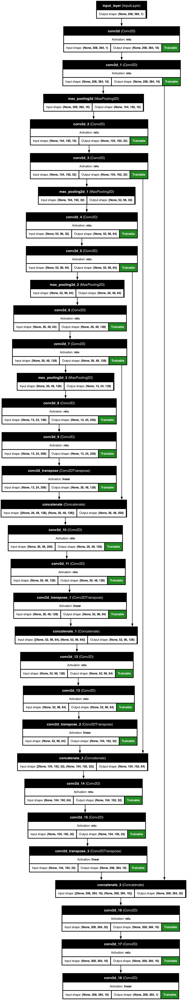

Architecture figure saved to:
../results/01_unet_turbulent_superresolution/figures/unet_architecture.png


In [21]:
# =========================================================
# Visualize U-Net architecture
#
# Purely for inspection: renders the encoder / bottleneck / decoder
# graph built in the cell above, including the skip-connection
# concatenations, using Keras' plot_model (requires graphviz + pydot).
# =========================================================

from pathlib import Path
import tensorflow as tf
from IPython.display import Image, display

# Output folder
figure_dir = RESULTS_DIR / "figures"
figure_dir.mkdir(exist_ok=True)

architecture_file = figure_dir / "unet_architecture.png"

tf.keras.utils.plot_model(
    unet_model,
    to_file=str(architecture_file),
    show_shapes=True,
    show_dtype=False,
    show_layer_names=True,
    rankdir="TB",                 # "TB" = top to bottom, "LR" = left to right
    expand_nested=True,
    dpi=150,
    show_layer_activations=True,
    show_trainable=True
)

display(Image(filename=str(architecture_file)))

print("Architecture figure saved to:")
print(architecture_file)

# 16. Train the U-Net

We train the U-Net using mean squared error.

We also use `EarlyStopping` to stop training when the validation loss stops improving.

For a first class example, we use a modest model:

```text
base_filters = 16
batch_size = 4
```

If training is too slow, reduce:

```text
base_filters
batch_size
number of planes
```


**Checkpoints and animation hook.** Before the training cell I add checkpoints for the main training (the best model by validation loss and a periodic checkpoint every 5 epochs, in the models folder) and a snapshot collector for the training animation: after every epoch it keeps the super-resolved field of one fixed validation plane, its error and the losses. The training cell adds these callbacks to the notebook's own early stopping and learning-rate schedule; nothing else changes.

In [22]:
import os
from pathlib import Path
EX_CKPT = MODELS_DIR / "checkpoints"; EX_CKPT.mkdir(parents=True, exist_ok=True)
class ExPeriodicCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, path, every): super().__init__(); self.path, self.every = path, max(1, int(every))
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0: self.model.save_weights(str(self.path))
def ex_ckpt_callbacks(name, epochs, monitor="val_loss"):
    return [tf.keras.callbacks.ModelCheckpoint(str(EX_CKPT / f"{name}_best.weights.h5"), monitor=monitor, save_best_only=True, save_weights_only=True),
            ExPeriodicCheckpoint(EX_CKPT / f"{name}_periodic.weights.h5", epochs // 10)]

anim_idx = len(X_val) // 2                          # fixed validation plane
anim_ny0 = int(plane_shape[0])
anim_x = X_val[anim_idx:anim_idx + 1]
anim_mean, anim_std = float(np.ravel(channel_mean)[0]), float(np.ravel(channel_std)[0])
anim_ref = y_val[anim_idx, :anim_ny0, :, 0] * anim_std + anim_mean            # physical u
anim_interp = X_val[anim_idx, :anim_ny0, :, 0] * anim_std + anim_mean
_, anim_coarse = create_coarse_input(y_val_raw[anim_idx], super_resolution_factor=super_resolution_factor)
anim_coarse = anim_coarse[:int(np.ceil(anim_ny0 / super_resolution_factor)), :, 0]   # true low-res grid
anim_interp_val_mse = float(np.mean((X_val - y_val) ** 2))                     # interpolation baseline, validation set

class AnimSnapshots(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__(); self.snaps = []; self.loss = []; self.val = []
    def _snap(self, e):
        p = self.model(anim_x, training=False).numpy()[0, :anim_ny0, :, 0] * anim_std + anim_mean
        self.snaps.append(dict(epoch=e, pred=p, err=p - anim_ref, loss=list(self.loss), val=list(self.val),
                               sample_mse=float(np.mean(((p - anim_ref) / anim_std) ** 2))))
    def on_train_begin(self, logs=None): self._snap(0)
    def on_epoch_end(self, epoch, logs=None):
        self.loss.append(float(logs["loss"])); self.val.append(float(logs["val_loss"])); self._snap(epoch + 1)

ANIM_CB = AnimSnapshots()
def ex_main_callbacks(name): return ex_ckpt_callbacks(name, 50) + [ANIM_CB]

In [23]:
# =========================================================
# Train the U-Net
# =========================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6
)

history = unet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,  # the notebook sets 50; 50 epochs take about 82 min on my laptop's GPU, so I run 25
    callbacks=[early_stopping, reduce_lr] + ex_main_callbacks("unet_sr"),  # checkpoints and animation snapshots
)

Epoch 1/25


2026-10-13 04:58:54.127119: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


   1/1011 ━━━━━━━━━━━━━━━━━━━━ 1:35:10 6s/step - loss: 1.0420 - mae: 0.8196

   2/1011 ━━━━━━━━━━━━━━━━━━━━ 2:06 125ms/step - loss: 0.9760 - mae: 0.7911

   3/1011 ━━━━━━━━━━━━━━━━━━━━ 2:00 120ms/step - loss: 0.9137 - mae: 0.7619

...

1008/1011 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - loss: 2.4056e-04 - mae: 0.0092

1009/1011 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - loss: 2.4056e-04 - mae: 0.0092

1010/1011 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - loss: 2.4056e-04 - mae: 0.0092

1011/1011 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - loss: 2.4055e-04 - mae: 0.0092

1011/1011 ━━━━━━━━━━━━━━━━━━━━ 108s 107ms/step - loss: 2.4055e-04 - mae: 0.0092 - val_loss: 2.8072e-04 - val_mae: 0.0096 - learning_rate: 1.2500e-05


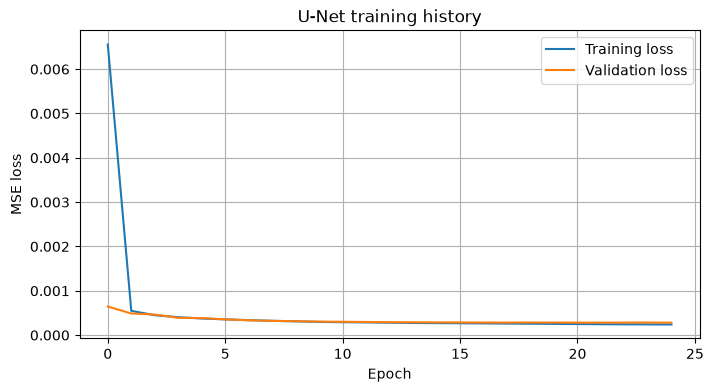

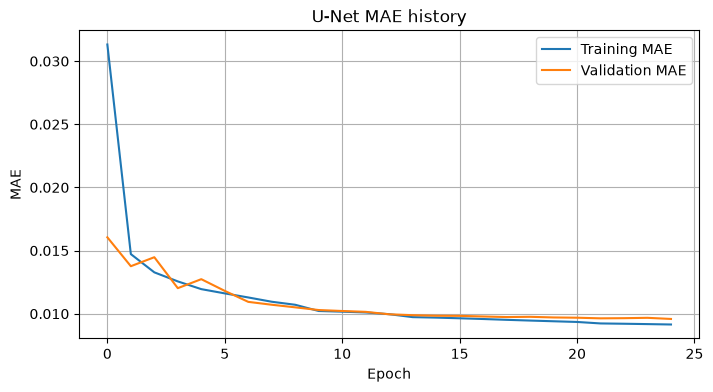

In [24]:
# =========================================================
# Plot training history
# =========================================================

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("U-Net training history")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("U-Net MAE history")
plt.legend()
plt.grid(True)
plt.show()

# 17. Save the Trained Model and Metadata

We save three things together, since all three are required to reuse the model later:

```text
1. the Keras model itself       (architecture + trained weights)
2. the normalization statistics (channel_mean, channel_std)
3. experiment metadata          (shapes, dataset sizes, final losses, ...)
```

The normalization statistics are essential: without them, any new input field cannot be
scaled the same way the training data was, and the model's predictions would be meaningless.


In [25]:
# =========================================================
# Save trained U-Net model and training metadata
# =========================================================

from pathlib import Path
import json
import numpy as np

# ---------------------------------------------------------
# Output directory
# ---------------------------------------------------------

model_dir = MODELS_DIR
model_dir.mkdir(exist_ok=True)

model_name = "unet_u_super_resolution"

model_file = model_dir / f"{model_name}.keras"
metadata_file = model_dir / f"{model_name}_metadata.json"
normalization_file = model_dir / f"{model_name}_normalization.npz"

# ---------------------------------------------------------
# Save Keras model
# ---------------------------------------------------------
#
# This saves:
#   - model architecture
#   - trained weights
#   - optimizer state
#   - compile information

unet_model.save(model_file)

print("Model saved to:")
print(model_file)

# ---------------------------------------------------------
# Save normalization statistics
# ---------------------------------------------------------
#
# These are essential.
# Without them, future inputs cannot be normalized in the same way.

np.savez_compressed(
    normalization_file,
    channel_mean=channel_mean,
    channel_std=channel_std
)

print("\nNormalization statistics saved to:")
print(normalization_file)

# ---------------------------------------------------------
# Save experiment metadata
# ---------------------------------------------------------

metadata = {
    "model_name": model_name,
    "model_file": str(model_file),
    "normalization_file": str(normalization_file),

    "task": "u velocity field super-resolution",
    "input": "coarse/interpolated u(y,x) field",
    "output": "high-resolution u(y,x) field",

    "variable": "u",
    "input_shape": list(X_train.shape[1:]),
    "output_shape": list(y_train.shape[1:]),

    "super_resolution_factor": int(super_resolution_factor),
    "padding_multiple": 16,

    "n_train_samples": int(len(X_train)),
    "n_val_samples": int(len(X_val)),
    "n_test_samples": int(len(X_test)),

    "baseline_mse": float(baseline_mse),
    "baseline_mae": float(baseline_mae),

    "final_training_loss": float(history.history["loss"][-1]),
    "final_validation_loss": float(history.history["val_loss"][-1]),

    "final_training_mae": float(history.history["mae"][-1]),
    "final_validation_mae": float(history.history["val_mae"][-1]),
}

with open(metadata_file, "w") as file:
    json.dump(metadata, file, indent=4)

print("\nMetadata saved to:")
print(metadata_file)

Model saved to:
../models/01_unet_turbulent_superresolution/unet_u_super_resolution.keras

Normalization statistics saved to:
../models/01_unet_turbulent_superresolution/unet_u_super_resolution_normalization.npz

Metadata saved to:
../models/01_unet_turbulent_superresolution/unet_u_super_resolution_metadata.json


# 18. Load a Trained Model (Optional / For Later Sessions)

This section shows how to reload the model, its normalization statistics, and its
metadata from disk, without repeating the training in Section 16. This is convenient
if you want to come back to evaluation (Sections 19-22) in a later session, or share
a trained model with someone else.


In [26]:
# =========================================================
# Load trained U-Net model
# =========================================================

from pathlib import Path
import numpy as np
import tensorflow as tf
import json

model_dir = MODELS_DIR

model_file = model_dir / "unet_u_super_resolution.keras"
metadata_file = model_dir / "unet_u_super_resolution_metadata.json"
normalization_file = model_dir / "unet_u_super_resolution_normalization.npz"

# Load model
loaded_unet = tf.keras.models.load_model(model_file)

print("Model loaded:")
print(model_file)

# Load normalization statistics
norm_data = np.load(normalization_file)

channel_mean = norm_data["channel_mean"]
channel_std = norm_data["channel_std"]

print("\nNormalization loaded:")
print("channel_mean:", channel_mean.reshape(-1))
print("channel_std:", channel_std.reshape(-1))

# Load metadata
with open(metadata_file, "r") as file:
    metadata = json.load(file)

print("\nMetadata:")
for key, value in metadata.items():
    print(f"{key}: {value}")

Model loaded:
../models/01_unet_turbulent_superresolution/unet_u_super_resolution.keras

Normalization loaded:
channel_mean: [0.7843925]
channel_std: [0.34103304]

Metadata:
model_name: unet_u_super_resolution
model_file: ../models/01_unet_turbulent_superresolution/unet_u_super_resolution.keras
normalization_file: ../models/01_unet_turbulent_superresolution/unet_u_super_resolution_normalization.npz
task: u velocity field super-resolution
input: coarse/interpolated u(y,x) field
output: high-resolution u(y,x) field
variable: u
input_shape: [208, 384, 1]
output_shape: [208, 384, 1]
super_resolution_factor: 4
padding_multiple: 16
n_train_samples: 4043
n_val_samples: 866
n_test_samples: 868
baseline_mse: 0.0013184553245082498
baseline_mae: 0.023546777665615082
final_training_loss: 0.00023942289408296347
final_validation_loss: 0.0002807238488458097
final_training_mae: 0.009147316217422485
final_validation_mae: 0.009585987776517868


Loaded model:
UNet_Turbulent_Field_SuperResolution

Current working directory:
<repo>/notebooks

Figure directory:
../results/01_unet_turbulent_superresolution/figures

Output file:
../results/01_unet_turbulent_superresolution/figures/loaded_unet_architecture.png

Graphviz dot executable:
/opt/homebrew/bin/dot



File created: True


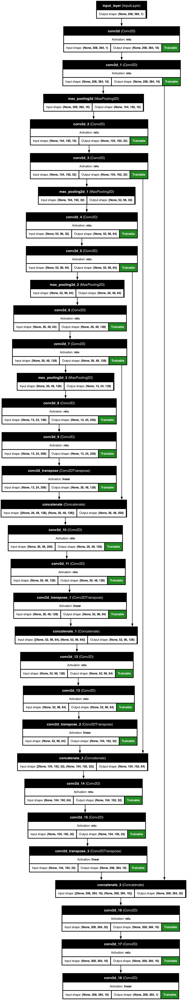

In [27]:
# =========================================================
# Plot loaded U-Net architecture safely
#
# Same idea as Section 15, but wrapped in a try/except and with an
# explicit graphviz check, since this is often run in a fresh
# environment where graphviz may not be installed.
# =========================================================

from pathlib import Path
from IPython.display import Image, display
import tensorflow as tf
import shutil

# ---------------------------------------------------------
# Check that the model exists
# ---------------------------------------------------------

print("Loaded model:")
print(loaded_unet.name)

# ---------------------------------------------------------
# Output folder
# ---------------------------------------------------------

figure_dir = RESULTS_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

architecture_file = figure_dir / "loaded_unet_architecture.png"

print("\nCurrent working directory:")
print(Path.cwd())

print("\nFigure directory:")
print(figure_dir)

print("\nOutput file:")
print(architecture_file)

# ---------------------------------------------------------
# Check Graphviz
# ---------------------------------------------------------

dot_path = shutil.which("dot")

print("\nGraphviz dot executable:")
print(dot_path)

if dot_path is None:
    print("\nWARNING: Graphviz is not available in the system PATH.")
    print("The model plot may not be created.")
    print("On Windows, install Graphviz and restart Jupyter/VS Code.")
    print("With conda, try:")
    print("conda install graphviz python-graphviz pydot")
    print("With pip, try:")
    print("pip install pydot graphviz")

# ---------------------------------------------------------
# Try to create the plot
# ---------------------------------------------------------

try:
    tf.keras.utils.plot_model(
        loaded_unet,
        to_file=str(architecture_file),
        show_shapes=True,
        show_layer_names=True,
        show_layer_activations=True,
        show_trainable=True,
        rankdir="TB",
        dpi=150
    )

    print("\nFile created:", architecture_file.exists())

    if architecture_file.exists():
        display(Image(filename=str(architecture_file)))
    else:
        print("\nThe file was not created. This is probably a Graphviz/pydot issue.")

except Exception as error:
    print("\nCould not plot the model.")
    print("Error:")
    print(error)

# 19. Evaluate on the Test Set

We evaluate the trained U-Net on test planes that were not used during training.

We compare:

```text
baseline interpolation
U-Net prediction
```

The goal is that the U-Net has lower error than the interpolation baseline.


In [28]:
# =========================================================
# Evaluate U-Net on the test set
# =========================================================

test_loss, test_mae = unet_model.evaluate(test_ds)

print("U-Net test loss:", test_loss)
print("U-Net test MAE:", test_mae)

print("\nBaseline interpolation MSE:", baseline_mse)
print("Baseline interpolation MAE:", baseline_mae)

if test_mae < baseline_mae:
    print("\nThe U-Net improves the interpolation baseline.")
else:
    print("\nThe U-Net does not improve the interpolation baseline yet.")

  1/217 ━━━━━━━━━━━━━━━━━━━━ 49s 230ms/step - loss: 2.3019e-04 - mae: 0.0088

  2/217 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 2.3931e-04 - mae: 0.0090  

  9/217 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.3955e-04 - mae: 0.0090 

 15/217 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.4073e-04 - mae: 0.0090

 21/217 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.4251e-04 - mae: 0.0090

...

201/217 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.6198e-04 - mae: 0.0093

208/217 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.6194e-04 - mae: 0.0093

215/217 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.6192e-04 - mae: 0.0093

217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 2.6193e-04 - mae: 0.0093


U-Net test loss: 0.0002628417278174311
U-Net test MAE: 0.009286783635616302

Baseline interpolation MSE: 0.0013184553
Baseline interpolation MAE: 0.023546778

The U-Net improves the interpolation baseline.


# 20. Predict One Test Plane

We now predict one test sample.

The prediction is first obtained in normalized units.

Then we convert it back to the original velocity scale:

```text
original = normalized × std + mean
```

We compare:

```text
high-resolution target
coarse/interpolated input
U-Net prediction
error fields
```


In [29]:
# =========================================================
# Predict one test plane using X_test
# =========================================================

test_index = 0

x_input_norm = X_test[test_index:test_index + 1]
y_true_norm = y_test[test_index:test_index + 1]

y_pred_norm = unet_model.predict(x_input_norm)

# Convert back to original physical scale.
x_input = x_input_norm * channel_std + channel_mean
y_true = y_true_norm * channel_std + channel_mean
y_pred = y_pred_norm * channel_std + channel_mean

x_input = x_input[0]
y_true = y_true[0]
y_pred = y_pred[0]

print("Input shape:", x_input.shape)
print("Target shape:", y_true.shape)
print("Prediction shape:", y_pred.shape)

# Crop back to original size for visualization if desired.
x_input_crop = crop_field_to_original_size(
    x_input,
    original_shape=plane_shape
)

y_true_crop = crop_field_to_original_size(
    y_true,
    original_shape=plane_shape
)

y_pred_crop = crop_field_to_original_size(
    y_pred,
    original_shape=plane_shape
)

print("\nCropped input shape:", x_input_crop.shape)
print("Cropped target shape:", y_true_crop.shape)
print("Cropped prediction shape:", y_pred_crop.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step


Input shape: (208, 384, 1)
Target shape: (208, 384, 1)
Prediction shape: (208, 384, 1)

Cropped input shape: (201, 384, 1)
Cropped target shape: (201, 384, 1)
Cropped prediction shape: (201, 384, 1)


# 21. Visualize the Prediction

For one velocity component, we visualize:

```text
1. coarse/interpolated input
2. high-resolution target
3. U-Net prediction
4. U-Net error
5. interpolation error
```

This allows us to see whether the U-Net is reconstructing missing small-scale structures.


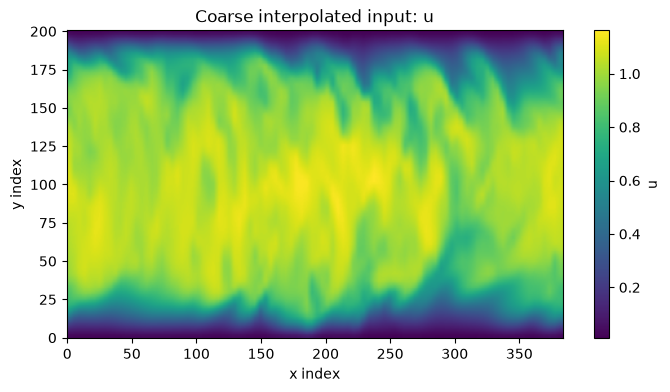

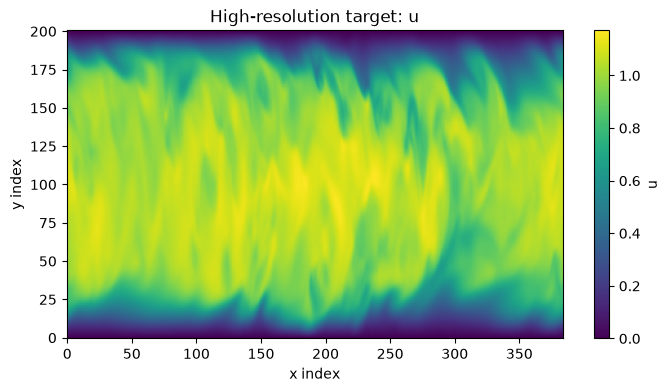

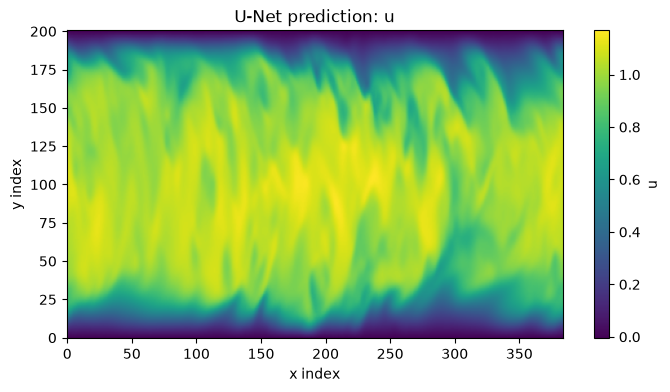

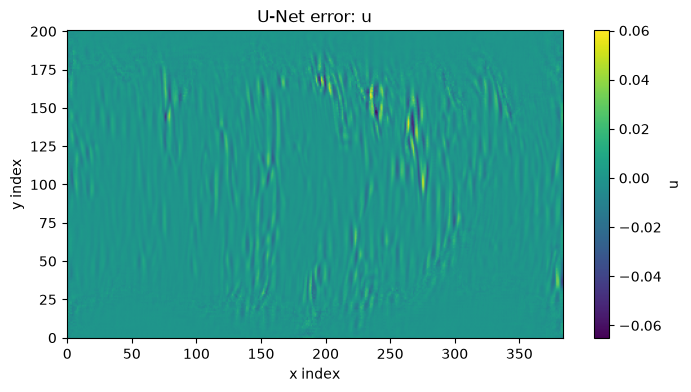

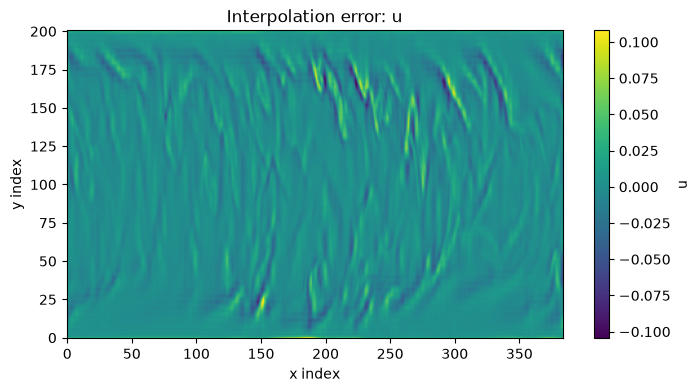

In [30]:
# =========================================================
# Visualize prediction for the u field
#
# Note: this notebook only uses u, so component_index is always 0
# and we label the plots directly as "u" (no component_names list
# is needed here).
# =========================================================

component_index = 0
component_name = "u"

coarse_component = x_input_crop[:, :, component_index]
true_component = y_true_crop[:, :, component_index]
pred_component = y_pred_crop[:, :, component_index]

unet_error = pred_component - true_component
baseline_error = coarse_component - true_component

plots = [
    (coarse_component, "Coarse interpolated input"),
    (true_component, "High-resolution target"),
    (pred_component, "U-Net prediction"),
    (unet_error, "U-Net error"),
    (baseline_error, "Interpolation error")
]

for field, title in plots:

    plt.figure(figsize=(8, 4))

    plt.imshow(
        field,
        origin="lower",
        aspect="auto"
    )

    plt.colorbar(label=component_name)
    plt.xlabel("x index")
    plt.ylabel("y index")
    plt.title(f"{title}: {component_name}")
    plt.show()

# 22. Reusable Function: Super-Resolution on Any Field

Sections 20-21 predicted on a single, already-preprocessed test sample (`X_test`,
`y_test`). Here we package the *entire* workflow into one function,
`study_super_resolution_from_field`, that takes any raw high-resolution field
(not necessarily from the test set) and runs it through padding, coarsening,
normalization, prediction, denormalization, cropping, and error computation.
This is convenient for trying the model on new snapshots later on.


In [31]:
# =========================================================
# Super-resolution study from one high-resolution field
# =========================================================

def study_super_resolution_from_field(
    high_field,
    unet_model,
    channel_mean,
    channel_std,
    super_resolution_factor=4,
    padding_multiple=16,
    verbose=True
):
    """
    Apply the trained U-Net super-resolution model to one high-resolution u field.

    The function does the complete workflow:

        high-resolution field
            ↓
        padding
            ↓
        artificial coarse graining
            ↓
        interpolation back to high-resolution size
            ↓
        normalization
            ↓
        U-Net prediction
            ↓
        denormalization
            ↓
        crop back to original size
            ↓
        error calculation

    Parameters
    ----------
    high_field:
        High-resolution u field.

        Accepted shapes:
            (n_y, n_x)
            (n_y, n_x, 1)

    unet_model:
        Trained Keras U-Net model.

    channel_mean:
        Training mean used for normalization.

    channel_std:
        Training standard deviation used for normalization.

    super_resolution_factor:
        Downsampling factor used to generate the coarse field.

    padding_multiple:
        Spatial size multiple needed by the U-Net.

    verbose:
        If True, print shapes and errors.

    Returns
    -------
    results:
        Dictionary containing:
            x_input_crop
            y_true_crop
            y_pred_crop
            coarse_up
            high_field_padded
            y_pred
            metrics
    """

    # -----------------------------------------------------
    # Make sure the field has a channel dimension
    # -----------------------------------------------------
    #
    # Keras expects image-like data:
    #
    #     (n_y, n_x, channels)
    #
    # Since we only use u, channels = 1.

    high_field = np.asarray(high_field, dtype=np.float32)

    if high_field.ndim == 2:
        high_field = high_field[..., np.newaxis]

    if high_field.ndim != 3:
        raise ValueError(
            "high_field must have shape (n_y, n_x) or (n_y, n_x, 1). "
            f"Received shape {high_field.shape}"
        )

    if high_field.shape[-1] != 1:
        raise ValueError(
            "This version expects only one channel: u. "
            f"Received {high_field.shape[-1]} channels."
        )

    # Original shape before padding
    original_shape = high_field.shape[:2]

    # -----------------------------------------------------
    # Pad high-resolution field
    # -----------------------------------------------------

    high_field_padded = pad_field_to_multiple(
        high_field,
        multiple=padding_multiple
    )

    # -----------------------------------------------------
    # Create coarse/interpolated input
    # -----------------------------------------------------
    #
    # coarse_up has the same shape as high_field_padded.
    #
    # This is the baseline prediction:
    #
    #     prediction = interpolation

    coarse_up, coarse_low = create_coarse_input(
        high_field_padded,
        super_resolution_factor=super_resolution_factor
    )

    # -----------------------------------------------------
    # Normalize input and target
    # -----------------------------------------------------
    #
    # Important:
    #
    # channel_mean and channel_std were computed from the training set.
    #
    # We add the batch dimension before normalization:
    #
    #     (n_y, n_x, 1) -> (1, n_y, n_x, 1)

    x_input_norm = (
        (coarse_up[np.newaxis, ...] - channel_mean) / channel_std
    ).astype(np.float32)

    y_true_norm = (
        (high_field_padded[np.newaxis, ...] - channel_mean) / channel_std
    ).astype(np.float32)

    # -----------------------------------------------------
    # Predict with U-Net
    # -----------------------------------------------------

    y_pred_norm = unet_model.predict(x_input_norm)

    # -----------------------------------------------------
    # Convert back to physical scale
    # -----------------------------------------------------

    x_input = x_input_norm * channel_std + channel_mean
    y_true = y_true_norm * channel_std + channel_mean
    y_pred = y_pred_norm * channel_std + channel_mean

    # Remove batch dimension
    x_input = x_input[0]
    y_true = y_true[0]
    y_pred = y_pred[0]

    # -----------------------------------------------------
    # Crop back to original size
    # -----------------------------------------------------

    x_input_crop = crop_field_to_original_size(
        x_input,
        original_shape=original_shape
    )

    y_true_crop = crop_field_to_original_size(
        y_true,
        original_shape=original_shape
    )

    y_pred_crop = crop_field_to_original_size(
        y_pred,
        original_shape=original_shape
    )

    # -----------------------------------------------------
    # Compute errors
    # -----------------------------------------------------

    baseline_error = x_input_crop - y_true_crop
    unet_error = y_pred_crop - y_true_crop

    baseline_mse = np.mean(baseline_error ** 2)
    baseline_mae = np.mean(np.abs(baseline_error))

    unet_mse = np.mean(unet_error ** 2)
    unet_mae = np.mean(np.abs(unet_error))

    metrics = {
        "baseline_mse": float(baseline_mse),
        "baseline_mae": float(baseline_mae),
        "unet_mse": float(unet_mse),
        "unet_mae": float(unet_mae)
    }

    if verbose:

        print("Original field shape:", high_field.shape)
        print("Padded field shape:", high_field_padded.shape)
        print("Coarse low-resolution shape:", coarse_low.shape)
        print("Coarse upsampled shape:", coarse_up.shape)

        print("\nNormalized input shape:", x_input_norm.shape)
        print("Normalized target shape:", y_true_norm.shape)
        print("Normalized prediction shape:", y_pred_norm.shape)

        print("\nCropped input shape:", x_input_crop.shape)
        print("Cropped target shape:", y_true_crop.shape)
        print("Cropped prediction shape:", y_pred_crop.shape)

        print("\nErrors:")
        print("Baseline MSE:", baseline_mse)
        print("Baseline MAE:", baseline_mae)
        print("U-Net MSE:", unet_mse)
        print("U-Net MAE:", unet_mae)

        if unet_mae < baseline_mae:
            print("\nThe U-Net improves the interpolated coarse input.")
        else:
            print("\nThe U-Net does not improve the interpolated coarse input for this field.")

    results = {
        "x_input_crop": x_input_crop,
        "y_true_crop": y_true_crop,
        "y_pred_crop": y_pred_crop,
        "coarse_low": coarse_low,
        "coarse_up": coarse_up,
        "high_field_padded": high_field_padded,
        "y_pred": y_pred,
        "metrics": metrics
    }

    return results

In [32]:
# =========================================================
# Apply U-Net super-resolution to one field
# =========================================================

# Example:
# high_field, metadata = read_one_h5_u_plane(
#     h5_file=example_item["file_path"],
#     add_channel=True
# )


example_field, example_metadata = read_velocity_plane_from_h5(
    h5_file=example_item["file_path"],
    return_metadata=True
)

high_field = example_field

results = study_super_resolution_from_field(
    high_field=high_field,
    unet_model=loaded_unet,
    channel_mean=channel_mean,
    channel_std=channel_std,
    super_resolution_factor=4,
    padding_multiple=16,
    verbose=True
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step


Original field shape: (201, 384, 1)
Padded field shape: (208, 384, 1)
Coarse low-resolution shape: (52, 96, 1)
Coarse upsampled shape: (208, 384, 1)

Normalized input shape: (1, 208, 384, 1)
Normalized target shape: (1, 208, 384, 1)
Normalized prediction shape: (1, 208, 384, 1)

Cropped input shape: (201, 384, 1)
Cropped target shape: (201, 384, 1)
Cropped prediction shape: (201, 384, 1)

Errors:
Baseline MSE: 0.00014906909
Baseline MAE: 0.008071804
U-Net MSE: 2.4255243e-05
U-Net MAE: 0.0029498471

The U-Net improves the interpolated coarse input.


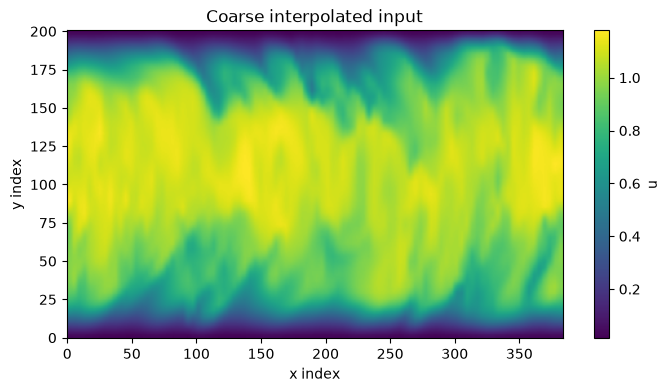

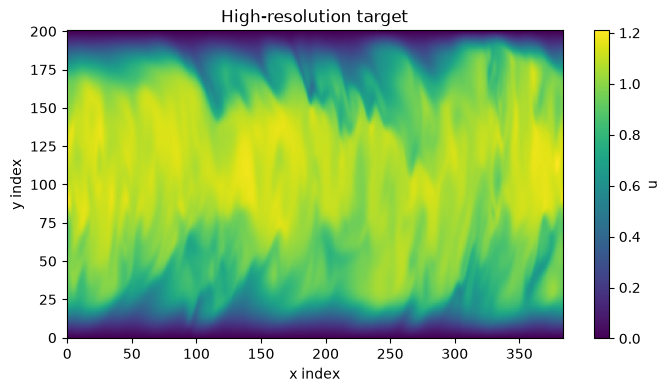

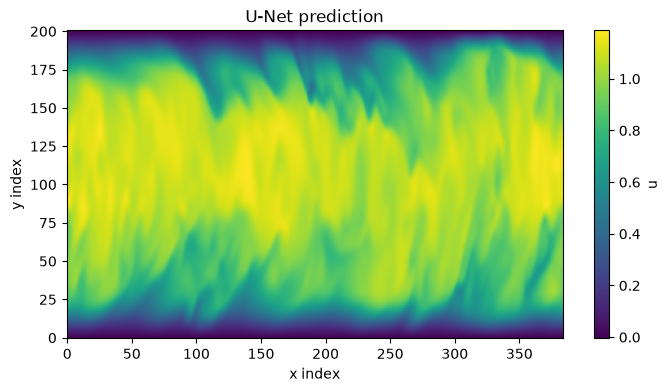

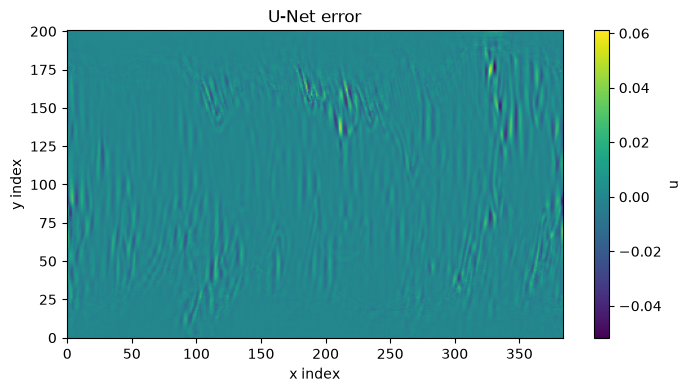

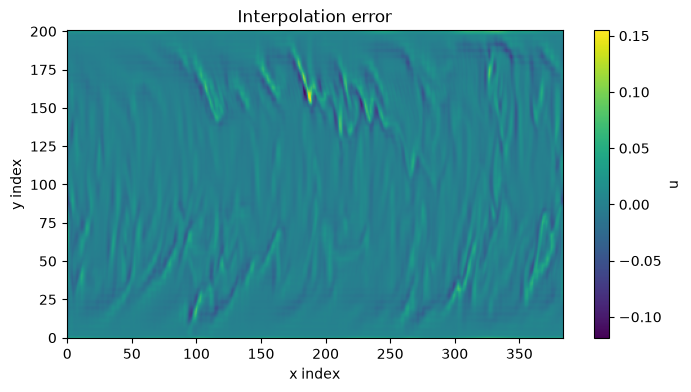

In [33]:
# =========================================================
# Visualize super-resolution result
# =========================================================

x_input_crop = results["x_input_crop"]
y_true_crop = results["y_true_crop"]
y_pred_crop = results["y_pred_crop"]

u_coarse = x_input_crop[:, :, 0]
u_true = y_true_crop[:, :, 0]
u_pred = y_pred_crop[:, :, 0]

u_unet_error = u_pred - u_true
u_baseline_error = u_coarse - u_true

plots = [
    (u_coarse, "Coarse interpolated input"),
    (u_true, "High-resolution target"),
    (u_pred, "U-Net prediction"),
    (u_unet_error, "U-Net error"),
    (u_baseline_error, "Interpolation error")
]

for field, title in plots:

    plt.figure(figsize=(8, 4))

    plt.imshow(
        field,
        origin="lower",
        aspect="auto"
    )

    plt.colorbar(label="u")
    plt.xlabel("x index")
    plt.ylabel("y index")
    plt.title(title)
    plt.show()

# 23. Optional: Residual Learning

A useful alternative is to train the U-Net to predict only the missing small scales.

Instead of:

```text
U-Net(coarse_up) ≈ high_resolution
```

we train:

```text
U-Net(coarse_up) ≈ high_resolution - coarse_up
```

Then the final prediction is:

```text
prediction = coarse_up + predicted_residual
```

This can be easier because the interpolation already contains the large scales.

The present notebook uses direct prediction for simplicity.

A good experiment is to modify the target as:

```python
y_residual = y_raw - X_raw
```

and train the model on the residual.


# 24. Experiments

## Experiment 1 — Change the super-resolution factor

Try:

```python
super_resolution_factor = 2
super_resolution_factor = 4
super_resolution_factor = 8
```

How does the difficulty change?

---

## Experiment 2 — Change the U-Net size

Try:

```python
base_filters = 8
base_filters = 16
base_filters = 32
```

Compare validation loss and test MAE.

---

## Experiment 3 — Residual learning

Train the U-Net to predict:

```text
high-resolution field - coarse/interpolated field
```

Then reconstruct:

```text
prediction = coarse/interpolated field + predicted residual
```

Compare direct prediction and residual prediction.

---

## Experiment 4 — One velocity component versus three components

Train one model using only:

```text
u
```

and another model using:

```text
u, v, w
```

Does using all components improve the reconstruction?

---

## Experiment 5 — Gradient-based error

In turbulence, small scales and gradients matter.

Compare not only the field error:

```text
MSE(u)
```

but also the gradient error:

```text
MSE(∂u/∂x) + MSE(∂u/∂y)
```

This is useful because a visually smooth field may still have poor small-scale gradients.


# Experiment solutions
I solve the five experiments of Section 24: (1) super-resolution factor 2, 4 and 8; (2) U-Net width `base_filters` = 8, 16, 32; (3) residual learning on top of the interpolated input; (4) one versus three velocity components; (5) a gradient-based error, both as an evaluation metric for every model and as an extra term in the training loss.

**Compute plan.** Every variant needs its own training, so all of them use a *reduced budget*: every second training plane (2,022 of 4,043), every second validation plane and at most 6 epochs, with the notebook's other settings (batch 4, Adam 1e-4 with `clipnorm=1`, MSE, early stopping with patience 8, learning-rate halving with patience 4). I score every model on the **full** test set (868 planes) in normalised units, next to the interpolation baseline at the same factor, and list the main model (`unet_model`, all training planes) as a reference row. Seven reduced trainings in all (factors 2/4/8, widths 8/32, residual, gradient loss), about 5–7 minutes each on my laptop's GPU.

In [34]:
import time, gc, csv
from pathlib import Path
ex_dir = EXERCISES_DIR; ex_dir.mkdir(exist_ok=True)

EX_EPOCHS = max(2, int(6 * float(__import__('os').environ.get('EX_BUDGET_SCALE', '1'))))   # exercise budget: at most 6 epochs (the main training runs 25)
EX_STRIDE = 2                      # keep every second training / validation plane
ex_ny0 = int(plane_shape[0])       # 201 physical rows; rows beyond are padding
ex_sample = 0                      # test plane used for the figures (as in Section 20)

def ex_write_csv(path, rows):
    with open(path, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)

def ex_coarsen(y_norm, factor, chunk=64):
    """Coarse/interpolated input for normalised targets: area down-sampling by `factor`,
    bilinear up-sampling back (the notebook's create_coarse_input, batched). Both resizes are
    weighted averages with weights summing to one, so they commute with the affine normalisation."""
    n, ny, nx, c = y_norm.shape
    out = np.empty_like(y_norm, dtype=np.float32)
    for i in range(0, n, chunk):
        yb = tf.convert_to_tensor(y_norm[i:i + chunk], dtype=tf.float32)
        cb = tf.image.resize(yb, size=(ny // factor, nx // factor), method="area")
        out[i:i + chunk] = tf.image.resize(cb, size=(ny, nx), method="bilinear").numpy()
    return out

def ex_make_ds(X, Y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if shuffle:
        ds = ds.cache().shuffle(buffer_size=len(X), seed=0)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def ex_train(name, X_tr, Y_tr, X_va, Y_va, base_filters=16, loss=None, epochs=EX_EPOCHS):
    np.random.seed(0); tf.random.set_seed(0)
    model = create_unet_super_resolution_model(input_shape=input_shape, output_channels=output_channels,
                                               base_filters=base_filters, dropout_rate=0.0, learning_rate=1e-4)
    if loss is not None:
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0), loss=loss, metrics=["mae"])
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)]
    t0 = time.time()
    h = model.fit(ex_make_ds(X_tr, Y_tr, True), validation_data=ex_make_ds(X_va, Y_va, False),
                  epochs=epochs, callbacks=cbs, verbose=2)
    dt = time.time() - t0
    print(f"[{name}] {len(h.history['loss'])} epochs, {dt/60:.1f} min, best val_loss {min(h.history['val_loss']):.3e}, "
          f"{model.count_params():,} parameters")
    return model, h.history, dt

def ex_evaluate(model, X_in, Y_ref, residual=False, chunk=16):
    """Field MSE/MAE over the padded plane (as in the notebook's evaluate) and gradient MSE,
    MSE(du/dx) + MSE(du/dy), with one-sided differences in grid-index units over the 201 physical rows.
    The same numbers are computed for the interpolation baseline (prediction = X_in)."""
    s = dict(mse=0.0, mae=0.0, gx=0.0, gy=0.0, b_mse=0.0, b_mae=0.0, b_gx=0.0, b_gy=0.0)
    n_f = n_gx = n_gy = 0; sample_pred = None
    for i in range(0, len(X_in), chunk):
        xb = X_in[i:i + chunk]; yb = Y_ref[i:i + chunk]
        pb = model(xb, training=False).numpy()
        if residual:
            pb = xb + pb
        if i <= ex_sample < i + chunk:
            sample_pred = pb[ex_sample - i, :ex_ny0, :, 0].copy()
        for key, qb in (("", pb), ("b_", xb)):
            e = qb - yb
            s[key + "mse"] += float(np.sum(e ** 2)); s[key + "mae"] += float(np.sum(np.abs(e)))
            ec = e[:, :ex_ny0, :, 0]
            s[key + "gx"] += float(np.sum(np.diff(ec, axis=2) ** 2)); s[key + "gy"] += float(np.sum(np.diff(ec, axis=1) ** 2))
        n_f += e.size; n_gx += ec[:, :, 1:].size; n_gy += ec[:, 1:, :].size
    r = dict(mse=s["mse"] / n_f, mae=s["mae"] / n_f, grad_mse=s["gx"] / n_gx + s["gy"] / n_gy,
             interp_mse=s["b_mse"] / n_f, interp_mae=s["b_mae"] / n_f, interp_grad_mse=s["b_gx"] / n_gx + s["b_gy"] / n_gy)
    return r, sample_pred

ex_Xtr4, ex_Ytr = X_train[::EX_STRIDE], y_train[::EX_STRIDE]
ex_Xva4, ex_Yva = X_val[::EX_STRIDE], y_val[::EX_STRIDE]
print("Reduced training / validation sets:", ex_Xtr4.shape, ex_Xva4.shape, "| test set:", X_test.shape)
print("Check ex_coarsen(factor 4) against the notebook's inputs, max |diff| =",
      float(np.abs(ex_coarsen(y_train[:8], 4) - X_train[:8]).max()))

ex_ref_metrics, ex_ref_pred = ex_evaluate(unet_model, X_test, y_test)
print("Main model on the test set:", {k: f"{v:.3e}" for k, v in ex_ref_metrics.items()})
ex_true_sample = y_test[ex_sample, :ex_ny0, :, 0]

Reduced training / validation sets: (2022, 208, 384, 1) (433, 208, 384, 1) | test set: (868, 208, 384, 1)
Check ex_coarsen(factor 4) against the notebook's inputs, max |diff| = 8.344650268554688e-07


Main model on the test set: {'mse': '2.628e-04', 'mae': '9.287e-03', 'grad_mse': '3.009e-04', 'interp_mse': '1.318e-03', 'interp_mae': '2.355e-02', 'interp_grad_mse': '6.946e-04'}


## Experiment 1 — solution
I regenerate the coarse input from the same normalised high-resolution targets with factor 2, 4 and 8 (grids 104×192, 52×96 and 26×48) and train one U-Net (`base_filters=16`) per factor with the reduced budget. I measure the difficulty on the full test set by the interpolation MSE (how much the coarsening removes) and by the ratio U-Net MSE / interpolation MSE (how much of it the network recovers).

Epoch 1/6


506/506 - 60s - 119ms/step - loss: 0.0162 - mae: 0.0442 - val_loss: 6.3068e-04 - val_mae: 0.0145 - learning_rate: 1.0000e-04


Epoch 2/6


506/506 - 54s - 106ms/step - loss: 4.3084e-04 - mae: 0.0122 - val_loss: 3.0994e-04 - val_mae: 0.0105 - learning_rate: 1.0000e-04


Epoch 3/6


...

506/506 - 55s - 108ms/step - loss: 0.0026 - mae: 0.0339 - val_loss: 0.0026 - val_mae: 0.0336 - learning_rate: 1.0000e-04


Epoch 6/6


506/506 - 55s - 108ms/step - loss: 0.0025 - mae: 0.0332 - val_loss: 0.0025 - val_mae: 0.0330 - learning_rate: 1.0000e-04


[factor 8] 6 epochs, 5.6 min, best val_loss 2.540e-03, 1,940,817 parameters


factor 2: interp MSE 1.719e-04, U-Net MSE 1.136e-04 (ratio 0.66), interp MAE 0.0080, U-Net MAE 0.0066
factor 4: interp MSE 1.318e-03, U-Net MSE 3.787e-04 (ratio 0.29), interp MAE 0.0235, U-Net MAE 0.0120
factor 8: interp MSE 7.044e-03, U-Net MSE 2.455e-03 (ratio 0.35), interp MAE 0.0588, U-Net MAE 0.0324


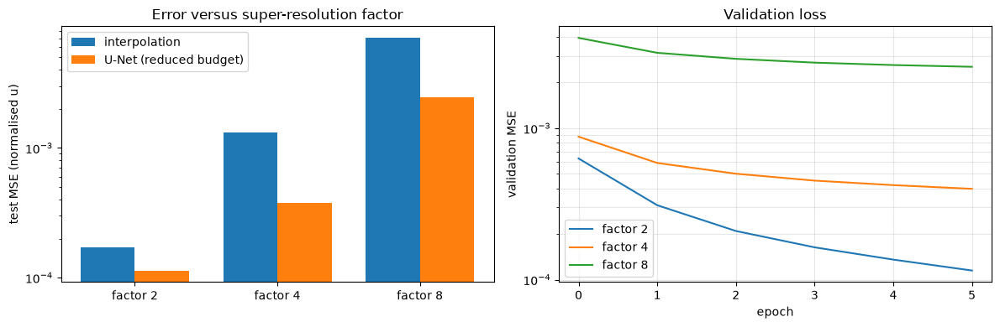

Result (Exercise 1): reduced budget (half the training planes, ≤6 epochs); test MSE interpolation -> U-Net: factor 2: 1.72e-04 -> 1.14e-04 (ratio 0.66); factor 4: 1.32e-03 -> 3.79e-04 (ratio 0.29); factor 8: 7.04e-03 -> 2.46e-03 (ratio 0.35)


In [35]:
ex1_rows, ex1_hist, ex1_pred, ex1_models = [], {}, {}, {}
for ex_f in (2, 4, 8):
    if ex_f == 4:
        ex_Xtr, ex_Xva, ex_Xte = ex_Xtr4, ex_Xva4, X_test
    else:
        ex_Xtr, ex_Xva, ex_Xte = ex_coarsen(ex_Ytr, ex_f), ex_coarsen(ex_Yva, ex_f), ex_coarsen(y_test, ex_f)
    ex_m, ex_h, ex_dt = ex_train(f"factor {ex_f}", ex_Xtr, ex_Ytr, ex_Xva, ex_Yva, base_filters=16)
    ex_r, ex_p = ex_evaluate(ex_m, ex_Xte, y_test)
    ex1_hist[ex_f], ex1_pred[ex_f] = ex_h, ex_p
    ex1_rows.append(dict(factor=ex_f, coarse_grid=f"{input_shape[0]//ex_f}x{input_shape[1]//ex_f}", epochs=len(ex_h["loss"]),
                         minutes=round(ex_dt / 60, 1), interp_mse=ex_r["interp_mse"], unet_mse=ex_r["mse"],
                         mse_ratio=ex_r["mse"] / ex_r["interp_mse"], interp_mae=ex_r["interp_mae"], unet_mae=ex_r["mae"],
                         interp_grad_mse=ex_r["interp_grad_mse"], unet_grad_mse=ex_r["grad_mse"]))
    if ex_f == 4:
        ex1_models[4] = ex_m; ex_f4_metrics = ex_r
    else:
        del ex_Xtr, ex_Xva, ex_Xte, ex_m
    gc.collect()
ex_write_csv(ex_dir / "ex1_factor.csv", ex1_rows)
for r in ex1_rows:
    print(f"factor {r['factor']}: interp MSE {r['interp_mse']:.3e}, U-Net MSE {r['unet_mse']:.3e} "
          f"(ratio {r['mse_ratio']:.2f}), interp MAE {r['interp_mae']:.4f}, U-Net MAE {r['unet_mae']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ex_x = np.arange(3); ex_w = 0.38
axes[0].bar(ex_x - ex_w / 2, [r["interp_mse"] for r in ex1_rows], ex_w, label="interpolation")
axes[0].bar(ex_x + ex_w / 2, [r["unet_mse"] for r in ex1_rows], ex_w, label="U-Net (reduced budget)")
axes[0].set_yscale("log"); axes[0].set_xticks(ex_x, [f"factor {r['factor']}" for r in ex1_rows])
axes[0].set_ylabel("test MSE (normalised u)"); axes[0].legend(); axes[0].set_title("Error versus super-resolution factor")
for ex_f in (2, 4, 8):
    axes[1].semilogy(ex1_hist[ex_f]["val_loss"], label=f"factor {ex_f}")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation MSE"); axes[1].legend(); axes[1].grid(alpha=0.3, which="both")
axes[1].set_title("Validation loss")
fig.tight_layout(); fig.savefig(ex_dir / "ex1_factor.png", dpi=120); plt.show()
print("Result (Exercise 1): reduced budget (half the training planes, ≤6 epochs); test MSE interpolation -> U-Net: "
      + "; ".join(f"factor {r['factor']}: {r['interp_mse']:.2e} -> {r['unet_mse']:.2e} (ratio {r['mse_ratio']:.2f})" for r in ex1_rows))

## Experiment 2 — solution
Three widths at factor 4 with the same reduced budget: `base_filters = 8, 16, 32` (the 16-filter run is the factor-4 run of Experiment 1). Doubling `base_filters` roughly quadruples the parameter count. I report the best validation loss, the test MSE and MAE, the parameters and the wall time.

Epoch 1/6


506/506 - 60s - 118ms/step - loss: 0.3078 - mae: 0.1707 - val_loss: 0.0044 - val_mae: 0.0370 - learning_rate: 1.0000e-04


Epoch 2/6


506/506 - 53s - 104ms/step - loss: 0.0028 - mae: 0.0303 - val_loss: 0.0018 - val_mae: 0.0256 - learning_rate: 1.0000e-04


Epoch 3/6


...

Epoch 5/6


506/506 - 64s - 127ms/step - loss: 4.0137e-04 - mae: 0.0125 - val_loss: 3.8109e-04 - val_mae: 0.0118 - learning_rate: 1.0000e-04


Epoch 6/6


506/506 - 65s - 128ms/step - loss: 3.7381e-04 - mae: 0.0120 - val_loss: 3.6178e-04 - val_mae: 0.0116 - learning_rate: 1.0000e-04


[base_filters 32] 6 epochs, 6.5 min, best val_loss 3.618e-04, 7,759,521 parameters


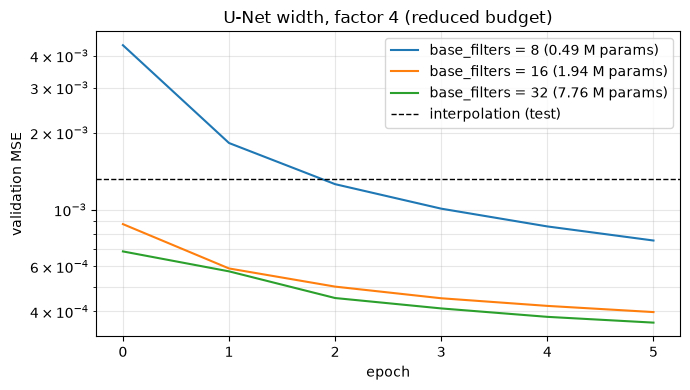

Result (Exercise 2): reduced budget, factor 4; base 8 (0.49 M, 5.4 min): best val 7.58e-04, test MAE 0.0170; base 16 (1.94 M, 5.6 min): best val 3.98e-04, test MAE 0.0120; base 32 (7.76 M, 6.5 min): best val 3.62e-04, test MAE 0.0113; main model (base 16, all training planes): test MAE 0.0093


In [36]:
ex2_rows, ex2_hist = [], {16: ex1_hist[4]}
ex2_info = {16: (ex1_models[4].count_params(), [r for r in ex1_rows if r["factor"] == 4][0]["minutes"], ex_f4_metrics)}
for ex_bf in (8, 32):
    ex_m, ex_h, ex_dt = ex_train(f"base_filters {ex_bf}", ex_Xtr4, ex_Ytr, ex_Xva4, ex_Yva, base_filters=ex_bf)
    ex_r, _ = ex_evaluate(ex_m, X_test, y_test)
    ex2_hist[ex_bf] = ex_h; ex2_info[ex_bf] = (ex_m.count_params(), round(ex_dt / 60, 1), ex_r)
    del ex_m; gc.collect()
for ex_bf in (8, 16, 32):
    ex_np, ex_min, ex_r = ex2_info[ex_bf]
    ex2_rows.append(dict(base_filters=ex_bf, parameters=ex_np, minutes=ex_min, epochs=len(ex2_hist[ex_bf]["loss"]),
                         best_val_loss=min(ex2_hist[ex_bf]["val_loss"]), test_mse=ex_r["mse"], test_mae=ex_r["mae"],
                         test_grad_mse=ex_r["grad_mse"]))
ex_write_csv(ex_dir / "ex2_size.csv", ex2_rows)

fig, ax = plt.subplots(figsize=(7, 4))
for ex_bf in (8, 16, 32):
    ax.semilogy(ex2_hist[ex_bf]["val_loss"], label=f"base_filters = {ex_bf} ({ex2_info[ex_bf][0]/1e6:.2f} M params)")
ax.axhline(ex_f4_metrics["interp_mse"], color="k", ls="--", lw=1, label="interpolation (test)")
ax.set_xlabel("epoch"); ax.set_ylabel("validation MSE"); ax.legend(); ax.grid(alpha=0.3, which="both")
ax.set_title("U-Net width, factor 4 (reduced budget)")
fig.tight_layout(); fig.savefig(ex_dir / "ex2_size.png", dpi=120); plt.show()
print("Result (Exercise 2): reduced budget, factor 4; "
      + "; ".join(f"base {r['base_filters']} ({r['parameters']/1e6:.2f} M, {r['minutes']} min): best val {r['best_val_loss']:.2e}, "
                  f"test MAE {r['test_mae']:.4f}" for r in ex2_rows)
      + f"; main model (base 16, all training planes): test MAE {ex_ref_metrics['mae']:.4f}")

## Experiment 3 — solution
I replace the target by the residual `y − X` (high-resolution minus interpolated field, in normalised units); the U-Net (`base_filters=16`, factor 4, reduced budget) learns it, and the prediction is `X + predicted residual`. Because MSE(residual) equals MSE(reconstruction), the losses compare directly with the direct run of Experiment 1 (same data, epochs and seed).

Epoch 1/6


506/506 - 63s - 125ms/step - loss: 0.0267 - mae: 0.0558 - val_loss: 9.4435e-04 - val_mae: 0.0199 - learning_rate: 1.0000e-04


Epoch 2/6


506/506 - 54s - 107ms/step - loss: 7.6886e-04 - mae: 0.0176 - val_loss: 6.6585e-04 - val_mae: 0.0162 - learning_rate: 1.0000e-04


Epoch 3/6


...

Epoch 5/6


506/506 - 57s - 112ms/step - loss: 4.7399e-04 - mae: 0.0134 - val_loss: 4.5993e-04 - val_mae: 0.0131 - learning_rate: 1.0000e-04


Epoch 6/6


506/506 - 61s - 121ms/step - loss: 4.3820e-04 - mae: 0.0128 - val_loss: 4.3021e-04 - val_mae: 0.0126 - learning_rate: 1.0000e-04


[residual] 6 epochs, 5.7 min, best val_loss 4.302e-04, 1,940,817 parameters


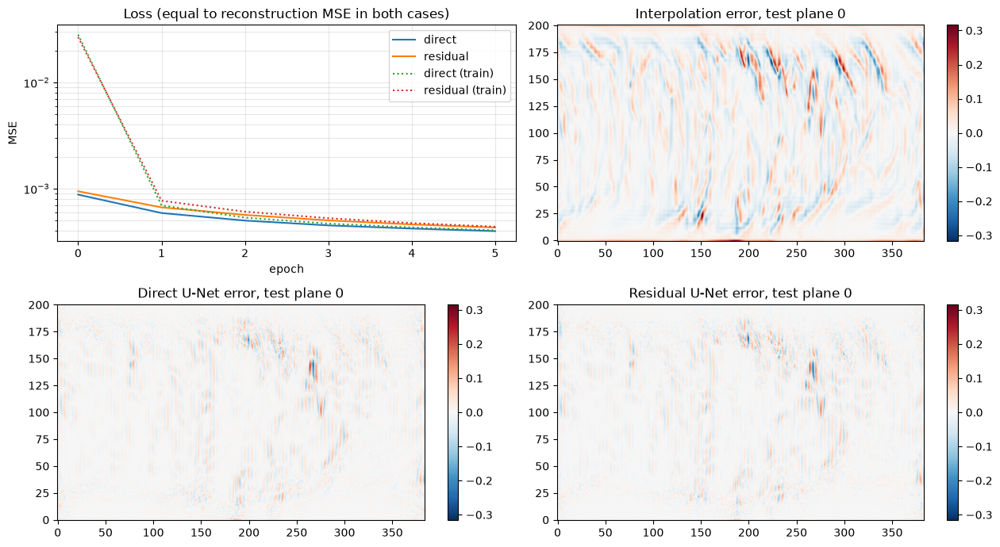

Result (Exercise 3): reduced budget, factor 4; test MSE interpolation 1.32e-03, direct 3.79e-04, residual 4.11e-04; best val loss direct 3.98e-04 vs residual 4.30e-04; main direct model (all planes) 2.63e-04


In [37]:
ex3_model, ex3_hist, ex3_dt = ex_train("residual", ex_Xtr4, ex_Ytr - ex_Xtr4, ex_Xva4, ex_Yva - ex_Xva4, base_filters=16)
ex3_r, ex3_pred = ex_evaluate(ex3_model, X_test, y_test, residual=True)
ex3_rows = [dict(model="interpolation", test_mse=ex3_r["interp_mse"], test_mae=ex3_r["interp_mae"], test_grad_mse=ex3_r["interp_grad_mse"]),
            dict(model="direct (reduced budget)", test_mse=ex_f4_metrics["mse"], test_mae=ex_f4_metrics["mae"], test_grad_mse=ex_f4_metrics["grad_mse"]),
            dict(model="residual (reduced budget)", test_mse=ex3_r["mse"], test_mae=ex3_r["mae"], test_grad_mse=ex3_r["grad_mse"]),
            dict(model="main model, direct (all planes)", test_mse=ex_ref_metrics["mse"], test_mae=ex_ref_metrics["mae"], test_grad_mse=ex_ref_metrics["grad_mse"])]
ex_write_csv(ex_dir / "ex3_residual.csv", ex3_rows)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes[0, 0].semilogy(ex1_hist[4]["val_loss"], label="direct"); axes[0, 0].semilogy(ex3_hist["val_loss"], label="residual")
axes[0, 0].semilogy(ex1_hist[4]["loss"], ":", label="direct (train)"); axes[0, 0].semilogy(ex3_hist["loss"], ":", label="residual (train)")
axes[0, 0].set_xlabel("epoch"); axes[0, 0].set_ylabel("MSE"); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3, which="both")
axes[0, 0].set_title("Loss (equal to reconstruction MSE in both cases)")
ex_emax = np.abs(X_test[ex_sample, :ex_ny0, :, 0] - ex_true_sample).max()
for ax, fld, ttl in ((axes[0, 1], X_test[ex_sample, :ex_ny0, :, 0] - ex_true_sample, "Interpolation error"),
                     (axes[1, 0], ex1_pred[4] - ex_true_sample, "Direct U-Net error"),
                     (axes[1, 1], ex3_pred - ex_true_sample, "Residual U-Net error")):
    im = ax.imshow(fld, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-ex_emax, vmax=ex_emax)
    ax.set_title(f"{ttl}, test plane {ex_sample}"); fig.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(ex_dir / "ex3_residual.png", dpi=120); plt.show()
print(f"Result (Exercise 3): reduced budget, factor 4; test MSE interpolation {ex3_r['interp_mse']:.2e}, direct {ex_f4_metrics['mse']:.2e}, "
      f"residual {ex3_r['mse']:.2e}; best val loss direct {min(ex1_hist[4]['val_loss']):.2e} vs residual {min(ex3_hist['val_loss']):.2e}; "
      f"main direct model (all planes) {ex_ref_metrics['mse']:.2e}")

## Experiment 4 — solution
This one cannot run with the data I have. Every plane file holds a single dataset `u(y, x)` (plus the `y` coordinate); there are no v or w planes, so a three-channel input `(u, v, w)` cannot be built. The cell below only checks this; no three-component model is trained. With v and w available the change would be small: stack the three components as channels, normalise each channel with its own mean and standard deviation, and set `output_channels=3` in `create_unet_super_resolution_model`. Whether the extra components help would then have to be measured on u alone.

In [38]:
import h5py
with h5py.File(plane_files[0]["file_path"], "r") as ex_fh:
    ex4_keys = list(ex_fh.keys())
ex4_names = sorted({p.name.split(".")[0] for p in planes_dir.glob("*.h5")})
print("Datasets in the first plane file:", ex4_keys)
print("Plane files found:", len(plane_files), "| file prefixes in the folder:", ex4_names)
print("Channels in the training arrays:", X_train.shape[-1])
print("Result (Exercise 4): not run — the planes contain only u "
      f"(datasets {ex4_keys}, {X_train.shape[-1]} channel), so no (u, v, w) model can be trained")

Datasets in the first plane file: ['u', 'y']
Plane files found: 5777 | file prefixes in the folder: ['P125_83pi']
Channels in the training arrays: 1
Result (Exercise 4): not run — the planes contain only u (datasets ['u', 'y'], 1 channel), so no (u, v, w) model can be trained


**Experiment 4 — outcome.** Not solved: the check above confirms that the planes hold only `u` (datasets `u`, `y`; one channel), so no (u, v, w) model can be trained.

## Experiment 5 — solution
Two parts. (a) I also evaluate every model above with the gradient error MSE(∂u/∂x) + MSE(∂u/∂y), computed with one-sided differences in grid-index units on the 201 physical rows (normalised u; the wall-normal grid is stretched, so ∂/∂y is per grid index, not per unit length). (b) I train a U-Net (`base_filters=16`, factor 4, reduced budget) with the loss MSE(u) + λ·[MSE(∂u/∂x) + MSE(∂u/∂y)], λ = 1, chosen so that both terms are of similar size, and compare it with the direct MSE-only run on both error measures.

Epoch 1/6


506/506 - 68s - 134ms/step - loss: 0.0667 - mae: 0.0884 - val_loss: 0.0027 - val_mae: 0.0212 - learning_rate: 1.0000e-04


Epoch 2/6


506/506 - 60s - 118ms/step - loss: 0.0019 - mae: 0.0182 - val_loss: 0.0015 - val_mae: 0.0163 - learning_rate: 1.0000e-04


Epoch 3/6


...

506/506 - 54s - 107ms/step - loss: 9.5767e-04 - mae: 0.0129 - val_loss: 9.2256e-04 - val_mae: 0.0126 - learning_rate: 1.0000e-04


Epoch 6/6


506/506 - 55s - 108ms/step - loss: 8.8022e-04 - mae: 0.0123 - val_loss: 8.6035e-04 - val_mae: 0.0122 - learning_rate: 1.0000e-04


[gradient loss] 6 epochs, 5.8 min, best val_loss 8.604e-04, 1,940,817 parameters


interpolation                                    field MSE 1.318e-03   gradient MSE 6.946e-04
main model, MSE loss (all planes)                field MSE 2.628e-04   gradient MSE 3.009e-04
direct, MSE loss (reduced)                       field MSE 3.787e-04   gradient MSE 5.224e-04
residual, MSE loss (reduced)                     field MSE 4.109e-04   gradient MSE 5.706e-04
direct, MSE + 1 x gradient loss (reduced)        field MSE 3.854e-04   gradient MSE 4.536e-04


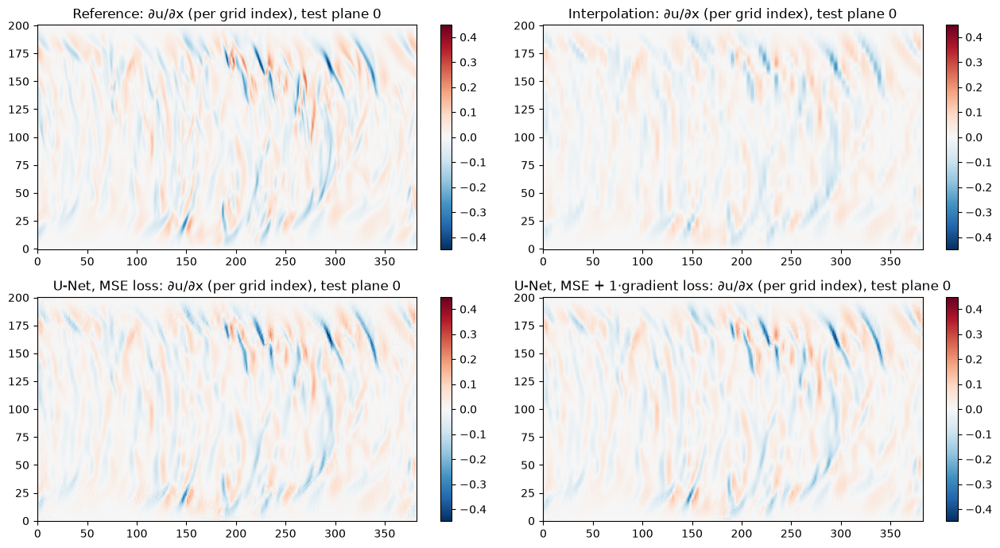

Result (Exercise 5): factor 4, normalised units; gradient MSE interpolation 6.95e-04, MSE-loss U-Net (reduced) 5.22e-04, gradient-loss U-Net (reduced, lambda=1) 4.54e-04, main model 3.01e-04; field MSE MSE-loss 3.79e-04 vs gradient-loss 3.85e-04


In [39]:
EX_LAMBDA = 1.0
def ex_gradient_loss(y_true, y_pred):
    e = y_pred - y_true
    ex_gx = e[:, :, 1:, :] - e[:, :, :-1, :]
    ex_gy = e[:, 1:, :, :] - e[:, :-1, :, :]
    return (tf.reduce_mean(tf.square(e), axis=[1, 2, 3])
            + EX_LAMBDA * (tf.reduce_mean(tf.square(ex_gx), axis=[1, 2, 3]) + tf.reduce_mean(tf.square(ex_gy), axis=[1, 2, 3])))

ex5_model, ex5_hist, ex5_dt = ex_train("gradient loss", ex_Xtr4, ex_Ytr, ex_Xva4, ex_Yva, base_filters=16, loss=ex_gradient_loss)
ex5_r, ex5_pred = ex_evaluate(ex5_model, X_test, y_test)
ex5_rows = [dict(model="interpolation", test_mse=ex5_r["interp_mse"], test_grad_mse=ex5_r["interp_grad_mse"]),
            dict(model="main model, MSE loss (all planes)", test_mse=ex_ref_metrics["mse"], test_grad_mse=ex_ref_metrics["grad_mse"]),
            dict(model="direct, MSE loss (reduced)", test_mse=ex_f4_metrics["mse"], test_grad_mse=ex_f4_metrics["grad_mse"]),
            dict(model="residual, MSE loss (reduced)", test_mse=ex3_r["mse"], test_grad_mse=ex3_r["grad_mse"]),
            dict(model=f"direct, MSE + {EX_LAMBDA:g} x gradient loss (reduced)", test_mse=ex5_r["mse"], test_grad_mse=ex5_r["grad_mse"])]
ex_write_csv(ex_dir / "ex5_gradient.csv", ex5_rows)
for r in ex5_rows:
    print(f"{r['model']:<48s} field MSE {r['test_mse']:.3e}   gradient MSE {r['test_grad_mse']:.3e}")

ex_gx_true = np.diff(ex_true_sample, axis=1)
ex_gmax = np.abs(ex_gx_true).max()
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, fld, ttl in ((axes[0, 0], ex_gx_true, "Reference"),
                     (axes[0, 1], np.diff(X_test[ex_sample, :ex_ny0, :, 0], axis=1), "Interpolation"),
                     (axes[1, 0], np.diff(ex1_pred[4], axis=1), "U-Net, MSE loss"),
                     (axes[1, 1], np.diff(ex5_pred, axis=1), f"U-Net, MSE + {EX_LAMBDA:g}·gradient loss")):
    im = ax.imshow(fld, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-ex_gmax, vmax=ex_gmax)
    ax.set_title(f"{ttl}: ∂u/∂x (per grid index), test plane {ex_sample}"); fig.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(ex_dir / "ex5_gradient.png", dpi=120); plt.show()
print(f"Result (Exercise 5): factor 4, normalised units; gradient MSE interpolation {ex5_r['interp_grad_mse']:.2e}, "
      f"MSE-loss U-Net (reduced) {ex_f4_metrics['grad_mse']:.2e}, gradient-loss U-Net (reduced, lambda={EX_LAMBDA:g}) {ex5_r['grad_mse']:.2e}, "
      f"main model {ex_ref_metrics['grad_mse']:.2e}; field MSE MSE-loss {ex_f4_metrics['mse']:.2e} vs gradient-loss {ex5_r['mse']:.2e}")

## Summary of the experiment solutions
- **Experiment 1:** interpolation error and U-Net error for factors 2, 4, 8; the printed ratios show how much of the interpolation error the U-Net removes at each factor (reduced budget). See `Result (Exercise 1)` and `ex1_factor.csv` in the experiments results folder.
- **Experiment 2:** validation loss, test MAE, parameter count and wall time for `base_filters` 8, 16, 32 are in `Result (Exercise 2)` and `ex2_size.csv`.
- **Experiment 3:** direct versus residual learning with identical data, epochs and seed: `Result (Exercise 3)` and `ex3_residual.csv`.
- **Experiment 4:** not run; the data contain only the u component.
- **Experiment 5:** gradient errors for all models and the effect of a gradient term in the loss: `Result (Exercise 5)` and `ex5_gradient.csv`.
- All variant trainings used half of the training planes and at most 6 epochs, so they are compared with each other; the main model, trained on all planes, is listed as a reference only.

# Animation — the U-Net learning to super-resolve u
The snapshots come from the main training itself (the hook before the training cell; no second run): after every epoch the super-resolved field of one fixed validation plane, its error and the losses. The dashboard video and its last frame go to the animations folder (`01_training_dashboard.mp4`, `01_final_frame.png`).

In [40]:
import pickle, time
from pathlib import Path
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = ANIM_DIR; anim_dir.mkdir(exist_ok=True)

anim_cb = ANIM_CB
pickle.dump(anim_cb.snaps, open(anim_dir / f"{ANIM_PREFIX}snapshots.pkl", "wb"))
anim_s = anim_cb.snaps[-1]
print(f"Main training: {len(anim_cb.snaps) - 1} epochs; final val loss {anim_s['val'][-1]:.3e} (interpolation on validation {anim_interp_val_mse:.3e})")

Main training: 25 epochs; final val loss 2.807e-04 (interpolation on validation 1.353e-03)


In [41]:
snaps = anim_cb.snaps; anim_n = max(snaps[-1]["epoch"], 1)
anim_vmin, anim_vmax = anim_ref.min(), anim_ref.max()
anim_ext = (-0.5, anim_ref.shape[1] - 0.5, -0.5, anim_ny0 - 0.5)
anim_interp_mse = float(np.mean(((anim_interp - anim_ref) / anim_std) ** 2))
anim_allv = [v for v in snaps[-1]["loss"] + snaps[-1]["val"]] + [anim_interp_val_mse]
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
kw = dict(origin="lower", aspect="auto", cmap="viridis", vmin=anim_vmin, vmax=anim_vmax, extent=anim_ext)
axes[0, 0].imshow(anim_coarse, interpolation="nearest", **kw)
axes[0, 0].set_title(f"Low-resolution input ({anim_coarse.shape[0]}×{anim_coarse.shape[1]}, factor {super_resolution_factor})")
anim_im = axes[0, 1].imshow(snaps[0]["pred"], **kw)
im_ref = axes[1, 0].imshow(anim_ref, **kw); axes[1, 0].set_title("Reference high-resolution u (201×384)")
for ax in (axes[0, 0], axes[0, 1], axes[1, 0]):
    ax.set_xlabel("x index"); ax.set_ylabel("y index")
fig.colorbar(im_ref, ax=[axes[0, 0], axes[0, 1], axes[1, 0]], label="u", shrink=0.6)
(anim_l1,) = axes[1, 1].semilogy([], [], label="training loss")
(anim_l2,) = axes[1, 1].semilogy([], [], label="validation loss")
axes[1, 1].axhline(anim_interp_val_mse, color="k", ls="--", lw=1, label="interpolation (validation)")
axes[1, 1].set_xlim(0, anim_n); axes[1, 1].set_ylim(min(anim_allv) * 0.7, max(anim_allv) * 1.5)
axes[1, 1].set_xlabel("epoch"); axes[1, 1].set_ylabel("MSE (normalised u)"); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3, which="both")
axes[1, 1].set_title("Loss curves")

def anim_draw(k):
    s = snaps[k]
    anim_im.set_data(s["pred"])
    axes[0, 1].set_title(f"U-Net prediction, epoch {s['epoch']}  (plane MSE {s['sample_mse']:.2e}, interp. {anim_interp_mse:.2e})")
    e = np.arange(1, len(s["loss"]) + 1)
    anim_l1.set_data(e, s["loss"]); anim_l2.set_data(e, s["val"])
    fig.suptitle(f"Stage 1 — U-Net super-resolution of u(y, x), factor {super_resolution_factor}: main training")
    return anim_im, anim_l1, anim_l2

anim_draw(len(snaps) - 1); fig.savefig(anim_dir / f"{ANIM_PREFIX}final_frame.png", dpi=110)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / f"{ANIM_PREFIX}training_dashboard.mp4",
                                                      writer=FFMpegWriter(fps=3, bitrate=2400), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

Animation: 26 frames written


**What the animation shows.** Top left: the true low-resolution field of one fixed validation plane (the 4× area-averaged grid the network has to undo). Top right: the U-Net's prediction for that plane after each epoch, starting from the untrained network at epoch 0; its title gives the plane's error against the interpolation error. Bottom left: the high-resolution reference. Bottom right: training and validation MSE per epoch, with the interpolation baseline on the validation set as a dashed line; the network is useful once the validation curve falls below that line, and the remaining gap shows how much of the small-scale content it has recovered.

# Three-seed repeats
I repeat every experiment training with the seeds 1 and 2; seed 0 is the run above (`ex_train` seeds NumPy and TensorFlow with 0 and shuffles with seed 0). `ex_train_s` is a copy of `ex_train` in which the seed drives the initial weights and the order of the batches; the data, the split and the reduced budget stay the same. I do not repeat the main training of Section 16: one run takes about 47 minutes here, so it stays a single run. Each row is one training; the summary gives the mean and the standard deviation over the three seeds. Tables `seeds_runs.csv` and `seeds_summary.csv` and the figure `seeds_summary.png` go to the experiments results folder; the three factor-4 direct models to the models folder.

In [42]:
import pandas as pd
SEEDS = (0, 1, 2)
def ex_make_ds_s(X, Y, shuffle, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if shuffle:
        ds = ds.cache().shuffle(buffer_size=len(X), seed=seed)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def ex_train_s(name, seed, X_tr, Y_tr, X_va, Y_va, base_filters=16, loss=None, epochs=EX_EPOCHS):
    np.random.seed(seed); tf.random.set_seed(seed)
    model = create_unet_super_resolution_model(input_shape=input_shape, output_channels=output_channels,
                                               base_filters=base_filters, dropout_rate=0.0, learning_rate=1e-4)
    if loss is not None:
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0), loss=loss, metrics=["mae"])
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)]
    t0 = time.time()
    h = model.fit(ex_make_ds_s(X_tr, Y_tr, True, seed), validation_data=ex_make_ds_s(X_va, Y_va, False, seed),
                  epochs=epochs, callbacks=cbs, verbose=0)
    dt = time.time() - t0
    print(f"[{name}, seed {seed}] {len(h.history['loss'])} epochs, {dt/60:.1f} min, best val_loss {min(h.history['val_loss']):.3e}", flush=True)
    return model, h.history, dt

seed_rows = []
def seed_row(variant, seed, r, hist, minutes):
    seed_rows.append(dict(variant=variant, seed=seed, test_mse=r["mse"], test_mae=r["mae"], test_grad_mse=r["grad_mse"],
                          best_val_loss=min(hist["val_loss"]), epochs=len(hist["loss"]), minutes=round(minutes, 1)))

# seed 0: the exercise runs above
for row in ex1_rows:
    seed_row(f"factor {row['factor']}", 0, dict(mse=row["unet_mse"], mae=row["unet_mae"], grad_mse=row["unet_grad_mse"]), ex1_hist[row["factor"]], row["minutes"])
for ex_bf in (8, 32):
    seed_row(f"base_filters {ex_bf}", 0, ex2_info[ex_bf][2], ex2_hist[ex_bf], ex2_info[ex_bf][1])
seed_row("residual", 0, ex3_r, ex3_hist, ex3_dt / 60)
seed_row("gradient loss", 0, ex5_r, ex5_hist, ex5_dt / 60)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
ex1_models[4].save(MODELS_DIR / "ex_factor4_seed0.keras")

# coarse inputs for factors 2 and 8, built once
ex_in = {4: (ex_Xtr4, ex_Xva4, X_test)}
for ex_f in (2, 8):
    ex_in[ex_f] = (ex_coarsen(ex_Ytr, ex_f), ex_coarsen(ex_Yva, ex_f), ex_coarsen(y_test, ex_f))

def ex_seed_runs(seed):
    for ex_f in (2, 4, 8):
        ex_Xtr, ex_Xva, ex_Xte = ex_in[ex_f]
        ex_m, ex_h, ex_dt = ex_train_s(f"factor {ex_f}", seed, ex_Xtr, ex_Ytr, ex_Xva, ex_Yva)
        ex_r, _ = ex_evaluate(ex_m, ex_Xte, y_test); seed_row(f"factor {ex_f}", seed, ex_r, ex_h, ex_dt / 60)
        if ex_f == 4:
            ex_m.save(MODELS_DIR / f"ex_factor4_seed{seed}.keras")
        del ex_m; gc.collect()
    for ex_bf in (8, 32):
        ex_m, ex_h, ex_dt = ex_train_s(f"base_filters {ex_bf}", seed, ex_Xtr4, ex_Ytr, ex_Xva4, ex_Yva, base_filters=ex_bf)
        ex_r, _ = ex_evaluate(ex_m, X_test, y_test); seed_row(f"base_filters {ex_bf}", seed, ex_r, ex_h, ex_dt / 60)
        del ex_m; gc.collect()
    ex_m, ex_h, ex_dt = ex_train_s("residual", seed, ex_Xtr4, ex_Ytr - ex_Xtr4, ex_Xva4, ex_Yva - ex_Xva4)
    ex_r, _ = ex_evaluate(ex_m, X_test, y_test, residual=True); seed_row("residual", seed, ex_r, ex_h, ex_dt / 60)
    del ex_m; gc.collect()
    ex_m, ex_h, ex_dt = ex_train_s("gradient loss", seed, ex_Xtr4, ex_Ytr, ex_Xva4, ex_Yva, loss=ex_gradient_loss)
    ex_r, _ = ex_evaluate(ex_m, X_test, y_test); seed_row("gradient loss", seed, ex_r, ex_h, ex_dt / 60)
    del ex_m; gc.collect()
    pd.DataFrame(seed_rows).to_csv(ex_dir / "seeds_runs.csv", index=False)


In [43]:
ex_seed_runs(1)   # seven trainings with seed 1

[factor 2, seed 1] 6 epochs, 5.7 min, best val_loss 8.966e-05


[factor 4, seed 1] 6 epochs, 5.8 min, best val_loss 4.294e-04


[factor 8, seed 1] 6 epochs, 5.9 min, best val_loss 2.473e-03


[base_filters 8, seed 1] 6 epochs, 5.5 min, best val_loss 1.077e-03


[base_filters 32, seed 1] 6 epochs, 6.3 min, best val_loss 3.503e-04


[residual, seed 1] 6 epochs, 5.3 min, best val_loss 4.032e-04


[gradient loss, seed 1] 6 epochs, 5.5 min, best val_loss 9.019e-04


In [44]:
ex_seed_runs(2)   # seven trainings with seed 2
seeds_runs = pd.DataFrame(seed_rows); seeds_runs.to_csv(ex_dir / "seeds_runs.csv", index=False)
print(seeds_runs.sort_values(["variant", "seed"]).to_string())

[factor 2, seed 2] 6 epochs, 5.4 min, best val_loss 9.741e-05


[factor 4, seed 2] 6 epochs, 5.4 min, best val_loss 4.745e-04


[factor 8, seed 2] 6 epochs, 5.5 min, best val_loss 2.484e-03


[base_filters 8, seed 2] 6 epochs, 5.0 min, best val_loss 7.944e-04


[base_filters 32, seed 2] 6 epochs, 6.3 min, best val_loss 3.491e-04


[residual, seed 2] 6 epochs, 5.4 min, best val_loss 4.006e-04


[gradient loss, seed 2] 6 epochs, 5.4 min, best val_loss 7.292e-04


            variant  seed  test_mse  test_mae  test_grad_mse  best_val_loss  epochs  minutes
4   base_filters 32     0  0.000344  0.011321       0.000489       0.000362       6      6.5
11  base_filters 32     1  0.000333  0.011084       0.000469       0.000350       6      6.3
18  base_filters 32     2  0.000331  0.011222       0.000450       0.000349       6      6.3
3    base_filters 8     0  0.000741  0.016965       0.001268       0.000758       6      5.4
10   base_filters 8     1  0.001060  0.020606       0.002270       0.001077       6      5.5
17   base_filters 8     2  0.000778  0.017526       0.001400       0.000794       6      5.0
0          factor 2     0  0.000114  0.006568       0.000338       0.000115       6      5.5
7          factor 2     1  0.000088  0.005633       0.000253       0.000090       6      5.7
14         factor 2     2  0.000096  0.006040       0.000279       0.000097       6      5.4
1          factor 4     0  0.000379  0.011993       0.000522       0.0

                 test_mse_mean  test_mse_std  test_mae_mean  test_mae_std  test_grad_mse_mean  test_grad_mse_std  best_val_loss_mean  best_val_loss_std  minutes_mean  minutes_std
variant                                                                                                                                                                           
factor 2              0.000099      0.000013       0.006080      0.000468            0.000290           0.000044            0.000101           0.000013      5.533333     0.152753
factor 4              0.000416      0.000039       0.012483      0.000613            0.000582           0.000082            0.000434           0.000039      5.600000     0.200000
factor 8              0.002414      0.000036       0.032115      0.000256            0.001305           0.000052            0.002499           0.000036      5.666667     0.208167
base_filters 8        0.000860      0.000175       0.018365      0.001960            0.001646           0

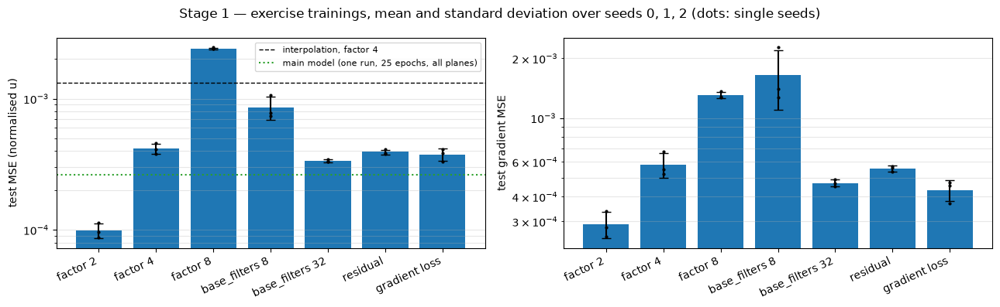

Result (three seeds): test MSE factor 2: 9.913e-05 ± 1.3e-05; factor 4: 4.156e-04 ± 3.9e-05; factor 8: 2.414e-03 ± 3.6e-05; base_filters 8: 8.598e-04 ± 1.7e-04; base_filters 32: 3.357e-04 ± 7.3e-06; residual: 3.926e-04 ± 1.6e-05; gradient loss: 3.758e-04 ± 3.9e-05; interpolation at factor 2 / 4 / 8: 1.719e-04 / 1.318e-03 / 7.044e-03


In [45]:
ex_order = ["factor 2", "factor 4", "factor 8", "base_filters 8", "base_filters 32", "residual", "gradient loss"]
seeds_summ = seeds_runs.groupby("variant")[["test_mse", "test_mae", "test_grad_mse", "best_val_loss", "minutes"]].agg(["mean", "std"]).loc[ex_order]
seeds_summ.columns = [f"{a}_{b}" for a, b in seeds_summ.columns]
seeds_summ.to_csv(ex_dir / "seeds_summary.csv"); print(seeds_summ.to_string())
ex_interp = {"factor 2": ex1_rows[0]["interp_mse"], "factor 8": ex1_rows[2]["interp_mse"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ex_x = np.arange(len(ex_order))
for ax, col, lab in ((axes[0], "test_mse", "test MSE (normalised u)"), (axes[1], "test_grad_mse", "test gradient MSE")):
    ax.bar(ex_x, seeds_summ[f"{col}_mean"], yerr=seeds_summ[f"{col}_std"], capsize=4, color="tab:blue")
    for s in SEEDS:
        v = seeds_runs[seeds_runs.seed == s].set_index("variant").loc[ex_order, col]
        ax.plot(ex_x, v, "k.", ms=4)
    ax.set_xticks(ex_x, ex_order, rotation=25, ha="right"); ax.set_yscale("log"); ax.set_ylabel(lab); ax.grid(alpha=0.3, which="both", axis="y")
axes[0].axhline(ex_ref_metrics["interp_mse"], color="k", ls="--", lw=1, label="interpolation, factor 4")
axes[0].axhline(ex_ref_metrics["mse"], color="tab:green", ls=":", lw=1.5, label="main model (one run, 25 epochs, all planes)")
axes[0].legend(fontsize=8)
fig.suptitle("Stage 1 — exercise trainings, mean and standard deviation over seeds 0, 1, 2 (dots: single seeds)")
fig.tight_layout(); fig.savefig(ex_dir / "seeds_summary.png", dpi=110); plt.show()
print("Result (three seeds): test MSE " + "; ".join(f"{v}: {r.test_mse_mean:.3e} ± {r.test_mse_std:.1e}" for v, r in seeds_summ.iterrows())
      + "; interpolation at factor 2 / 4 / 8: " + " / ".join(f"{x:.3e}" for x in (ex_interp["factor 2"], ex_ref_metrics["interp_mse"], ex_interp["factor 8"])))